# Домашнее задание по нейросетям в скоринге.

**ФИО**: Бартия Тимур Зурабович

**Данные для обучения**: 
1. [Шардированные данные для нейросети](https://www.kaggle.com/datasets/ahm352/t-intensive-nn-sequence-shards)
2. [Признаки для обучения бустинга](https://www.kaggle.com/datasets/ahm352/t-intensive-features)

**Сдать нужно**: ссылку на Kaggle Notebook. Либо `.ipynb` с outputs ячеек. Воспроизводимость ноута -- большой плюс. Если нейронку обучали на других мощностях (не в kaggle), то можно сохранить модель в kaggle и добавить обученную модель через Input Kaggle для воспроизводимости. 

Если сложности с сохранением модели - нужно прикрепить `.parquet / .csv` с предсказаниями финальной версии модели

За каждый эксперимент по **1.5** балла. Максимум за тип эксперимента **3** балла. Для каждого эксперимента должна быть описана гипотеза и выводы. За невоспроизводимость/сильное переобучение/ без вывода будут штрафы.

Улучшение нейросети будем оценивать в **1** балл за каждое увеличение в **0.0075** auc бейзлайна нейросети. Например, качество улучшилось с `0.69 -> 0.707`. Это оцениваем в **2** балла. Максимум - **4** основных балла (тк качество бустинга **0.72** auc).

За каждое улучшение в **0.01 auc** сверху **0.72 auc** добавляем **1** балл. Максимум **3** балла.

Максимально можно получить **5** дополнительных баллов.

В итоге работы написать отчет с выводами проделанной работы. Интерпретация результатов, краткое описание проделанных экспериментов и идеи для дальнейшего развития этой модели.

## Разбалловка: 20 основных

| Основная часть | Баллы |
|---|---:|
| Воспроизводимость ноута / возможность инференса модели, если обучена не в Kaggle. Run All ячеек на подвыборке отрабатывает | 2 |
| EDA данных. Сформулированы гипотезы, инсайты для дальнейших экспериментов | 1.5 |
| ≥2 эксперимента с данными | 3 |
| ≥2 эксперимента с моделью (архитектурой) | 3 |
| ≥2 эксперимента с loss/обучением | 3 |
| Исследования с артефактами, есть learning curves, логирования в процессе обучения | 1.5 |
| Побито качество (harmonic mean auc) бустинга на тесте | 4 |
| Проинтерпретированы аттрибуты транзакции с помощью permutation importance | 2 |

| **Итого** | **20.00** |

| Бонус | Баллы |
|---|---:|
| Обучена нейросеть с головой для предсказания непрерывного таргета | 3 |
| Качество нейросети на тесте (по harmonic mean auc) с непрерывным таргетом не меньше исходной | 1 |
| Дополнительное улучшение качества нейросети | 3 |
| Пайплайн препроцессинг -> обучение/валидация -> эксперимент. Процесс тестирования экспериментов оформлен в виде шаблонизированного кода | 1.5 |
| Добавлен сервис логирования экспериментов (tensorboard/clearml) | 1 |
| Дополнительные методы интерпретации | 2 |
| **Максимум** | **11.5** |

Критерий **Обучена нейросеть с головой для предсказания непрерывного таргета**:
Необходимо составить самостоятельно таргет - сумму транзакций за последние 30 дней до даты заявки. Его будем считать непрерывным таргетом. Будем предсказывать этот таргет по транзакциям, которые были **до 30 дней** до заявки, чтобы не произвести даталик. 

Далее будет необходимо составить мультитаск нейросеть, которая будет предсказывать и дефолт и сумму транзакций за последние 30 дней.

Лосс, метрики выбираются самостоятельно. Но дополнительно надо измерить harmonic mean auc только по бинарным таргетам.

In [427]:
from pathlib import Path
import hashlib
import json
import random
import time
from dataclasses import dataclass

import numpy as np
import pandas as pd
import polars as pl

import torch
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split

SEED = 42
MAX_SEQ_LEN, BATCH_SIZE, EPOCHS = 128, 256, 3

PREBUILT_DIR = Path(
    "/kaggle/input/datasets/ahm352/t-intensive-nn-sequence-shards"
)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Задание:

Обучить нейросеть с качеством (harmonic auc) выше бустинга на тесте: выше `0.721359`.

Датасет для обучения тут - https://www.kaggle.com/datasets/ahm352/t-intensive-nn-sequence-shards



In [428]:
with open("/kaggle/input/datasets/ahm352/t-intensive-nn-sequence-shards/preprocessing.json", "r", encoding="utf-8") as file:
    preprocessing = json.load(file)
with open("/kaggle/input/datasets/ahm352/t-intensive-nn-sequence-shards/manifest.json", "r", encoding="utf-8") as file:
    manifest = json.load(file)

In [429]:
from torch import nn
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence
from torch.utils.data import IterableDataset, DataLoader
from torch.utils.tensorboard import SummaryWriter
import matplotlib.pyplot as plt
import seaborn as sns

STORED_CAT_COLS = list(preprocessing["categorical_columns"])
STORED_CONT_COLS = list(preprocessing["continuous_columns"])
# Остальные признаки оставлены для домашки.
CAT_COLS = ["operation_kind", "mcc", "income_flag"]
CONT_COLS = ["amnt", "days_before"]

missing = (set(CAT_COLS) - set(STORED_CAT_COLS)) | (
    set(CONT_COLS) - set(STORED_CONT_COLS)
)

if missing:
    raise ValueError(f"Baseline-колонки отсутствуют в Dataset: {sorted(missing)}")

CAT_INDICES = np.asarray([STORED_CAT_COLS.index(c) for c in CAT_COLS])
CONT_INDICES = np.asarray([STORED_CONT_COLS.index(c) for c in CONT_COLS])

vocab_specs = preprocessing["vocabularies"]

STORED_VOCAB_SIZES = {
    column: int(vocab_specs[column]["size"]) for column in STORED_CAT_COLS
}

VOCAB_SIZES = {column: STORED_VOCAB_SIZES[column] for column in CAT_COLS}

In [430]:
def product_harmonic_auc(y_true, score, product,
                         expected_products=None):
    """Return harmonic product AUC together with its auditable table.

    Parameters
    ----------
    y_true, score, product : array-like
        Aligned targets, model scores and product labels.
    expected_products : collection or None
        Products that must participate in the harmonic mean.

    Returns
    -------
    tuple[float, pandas.DataFrame]
        Harmonic mean and the underlying per-product AUC table.
    """
    table = product_auc_table(y_true, score, product, expected_products)
    return harmonic_mean_auc(table["auc"]), table

In [431]:
def harmonic_mean_auc(values):
    """Compute the harmonic mean of product-level ROC-AUC values.

    Parameters
    ----------
    values : array-like
        One ROC-AUC value for every evaluated product.

    Returns
    -------
    float
        ``P / sum(1 / auc_p)``. A zero product AUC makes the result zero.

    Raises
    ------
    ValueError
        If the collection is empty, non-finite or outside ``[0, 1]``.
    """
    scores = np.asarray(values, dtype="float64")
    if scores.ndim != 1 or len(scores) == 0 or not np.isfinite(scores).all():
        raise ValueError("Нужен непустой конечный вектор product AUC")
    if np.any((scores < 0) | (scores > 1)):
        raise ValueError("ROC-AUC должен находиться в [0, 1]")
    if np.any(scores == 0):
        return 0.0
    return float(len(scores) / np.reciprocal(scores).sum())

In [432]:
def product_auc_table(y_true, score, product, expected_products=None):
    """Calculate ROC-AUC independently for every product.

    Parameters
    ----------
    y_true : array-like
        Binary targets.
    score : array-like
        Positive-class probabilities or monotonic decision scores.
    product : array-like
        Product label for each observation.
    expected_products : collection or None
        Products that must all be present; omission is an error.

    Returns
    -------
    pandas.DataFrame
        Columns ``product``, ``n`` and ``auc``, sorted by product.

    Raises
    ------
    ValueError
        If lengths differ or a product contains only one target class.
    """
    target, score, product = map(np.asarray, (y_true, score, product))
    if not (len(target) == len(score) == len(product)):
        raise ValueError("target, score и product должны иметь одну длину")
    frame = pd.DataFrame({"target": target, "score": score, "product": product})
    observed = set(frame["product"].unique())
    if expected_products is not None and observed != set(expected_products):
        raise ValueError(f"Набор продуктов {observed} != {set(expected_products)}")
    rows = []
    for value, group in frame.groupby("product", sort=True):
        if group["target"].nunique() != 2:
            raise ValueError(f"product={value}: ROC-AUC требует оба класса")
        rows.append({"product": value, "n": len(group),
                     "auc": roc_auc_score(group["target"], group["score"])})
    return pd.DataFrame(rows)

In [433]:
REQUIRED_SHARD_KEYS = {"app_id", "offsets", "lengths", "cats", "cont",
                       "target", "product_idx"}


In [434]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


In [435]:

class NpzSequenceDataset(IterableDataset):
    """Stream selected baseline features from full pre-encoded NPZ shards."""
    def __init__(self, files, shuffle=False, seed=SEED):
        """Configure files and deterministic epoch shuffling.

        Parameters
        ----------
        files : iterable[pathlib.Path]
            Shards from one split and optional products.
        shuffle : bool
            Shuffle train files and applications.
        seed : int
            Base seed, incremented per iterator pass.
        """
        self.files = list(files)
        self.shuffle, self.seed, self.epoch = shuffle, seed, 0
    def __iter__(self):
        """Yield only columns selected by ``CAT_INDICES``/``CONT_INDICES``."""
        rng = np.random.default_rng(self.seed + self.epoch)
        files = list(self.files)
        if self.shuffle:
            rng.shuffle(files)
            self.epoch += 1
        for path in files:
            with np.load(path, allow_pickle=False) as archive:
                data = {key: archive[key] for key in REQUIRED_SHARD_KEYS}
            order = np.arange(len(data["lengths"]))
            if self.shuffle:
                rng.shuffle(order)
            for index in order:
                start, stop = data["offsets"][index:index + 2]
                cats = data["cats"][start:stop][:, CAT_INDICES]
                cont = data["cont"][start:stop][:, CONT_INDICES]
                yield (torch.from_numpy(cats).long(), torch.from_numpy(cont).float(),
                       int(data["lengths"][index]), float(data["target"][index]),
                       int(data["product_idx"][index]), int(data["app_id"][index]))

In [436]:
def collate(items):
    """Pad variable-length applications within one mini-batch.

    Parameters
    ----------
    items : list[tuple]
        Six-tuples emitted by ``NpzSequenceDataset``.

    Returns
    -------
    dict[str, torch.Tensor]
        Padded features plus original lengths, targets, products and IDs.
    """
    cats, cont, lengths, target, product, app_id = zip(*items)
    return {
        "cats": pad_sequence(cats, batch_first=True),
        "cont": pad_sequence(cont, batch_first=True),
        "length": torch.tensor(lengths),
        "target": torch.tensor(target, dtype=torch.float32),
        "product": torch.tensor(product, dtype=torch.long),
        "app_id": torch.tensor(app_id, dtype=torch.long),
    }

In [437]:
def shard_paths(split, product_indices=None):
    """Resolve manifest entries for one split and optional products.

    Parameters
    ----------
    split : {"train", "valid", "test"}
        Dataset subset to read.
    product_indices : collection[int] or None
        Product buckets; ``None`` selects every product.

    Returns
    -------
    list[pathlib.Path]
        Existing NPZ paths in deterministic order.
    """
    if split not in manifest["shards"]:
        raise ValueError(f"Неизвестный split: {split}")
    groups = manifest["shards"][split]
    keys = sorted(groups, key=int)
    if product_indices is not None:
        keys = [str(index) for index in sorted(product_indices)]
    files = [
        PREBUILT_DIR / entry["path"]
        for key in keys for entry in groups.get(key, [])
    ]
    missing = [path for path in files if not path.is_file()]
    if missing:
        raise FileNotFoundError(f"Не найдены shards: {missing[:3]}")
    if not files:
        raise ValueError(f"Нет shards для split={split}, products={keys}")
    return files


In [438]:
loaders = {}

for split_name in ["train", "valid", "test"]:
    dataset = NpzSequenceDataset(
        shard_paths(split_name),
        shuffle=(split_name == "train"),
    )
    loaders[split_name] = DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        collate_fn=collate,
        pin_memory=(device.type == "cuda"),
    )

In [439]:
class MultiHeadLSTM(nn.Module):
    """Shared transaction encoder with one binary head per product."""
    def __init__(self, vocab_sizes, n_cont, n_products, emb_dim=12, hidden=64):
        """Construct embeddings, shared LSTM and product heads.
        Parameters
        ----------
        vocab_sizes : dict[str, int]
            Embedding sizes including PAD=0 and UNK=1.
        n_cont, n_products : int
            Continuous feature count and number of heads.
        emb_dim, hidden : int
            Embedding and LSTM hidden widths.
        """
        super().__init__()
        self.embeddings = nn.ModuleList([
            nn.Embedding(vocab_sizes[name], emb_dim, padding_idx=0)
            for name in CAT_COLS
        ])
        width = emb_dim * len(CAT_COLS) + n_cont
        self.encoder = nn.LSTM(width, hidden, batch_first=True)
        self.dropout = nn.Dropout(0.2)
        self.heads = nn.ModuleList([nn.Linear(hidden, 1)
                                    for _ in range(n_products)])
    def forward(self, cats, cont, lengths, product):
        """Encode histories and return each row's selected-head logit.

        Batch-first inputs are packed, so padding cannot alter the final
        shared state. The returned tensor has shape ``(B,)``.
        """
        embedded = [layer(cats[:, :, index])
                    for index, layer in enumerate(self.embeddings)]
        sequence = torch.cat([*embedded, cont], dim=-1)
        packed = pack_padded_sequence(
            sequence, lengths.cpu(), batch_first=True, enforce_sorted=False
        )
        _, (hidden, _) = self.encoder(packed)
        logits = torch.cat([head(self.dropout(hidden[-1]))
                            for head in self.heads], dim=1)
        return logits.gather(1, product[:, None]).squeeze(1)

In [440]:
def summed_product_bce(logits, target, product):
    """Sum mean binary cross-entropy over products present in a step.

    Parameters
    ----------
    logits, target : torch.Tensor
        Aligned one-dimensional model outputs and binary labels.
    product : torch.Tensor
        Integer product-head index for every row.

    Returns
    -------
    torch.Tensor
        Scalar ``sum_p mean(BCE_i | product_i=p)``.
    """
    if not (logits.ndim == target.ndim == product.ndim == 1):
        raise ValueError("logits, target и product должны быть векторами")
    if not (len(logits) == len(target) == len(product)) or len(logits) == 0:
        raise ValueError("Векторы loss должны иметь одну ненулевую длину")
    element_loss = nn.functional.binary_cross_entropy_with_logits(
        logits, target, reduction="none"
    )
    product_losses = [element_loss[product == index].mean()
                      for index in torch.unique(product, sorted=True)]
    return torch.stack(product_losses).sum()

In [441]:
product_values = preprocessing["product_values"]

In [442]:
model = MultiHeadLSTM(
    VOCAB_SIZES, len(CONT_COLS), len(product_values)
).to(device)

In [443]:
@torch.no_grad()
def evaluate(model, loader, expected_products=None):
    """Evaluate summed product BCE and harmonic product ROC-AUC.

    Parameters
    ----------
    model : torch.nn.Module
        Model compatible with batches returned by ``collate``.
    loader : torch.utils.data.DataLoader
        Validation or test sequence loader.
    expected_products : collection or None
        Product labels that must all be present in the split.

    Returns
    -------
    tuple
        Loss, H-AUC, targets, probabilities, app IDs and product labels.
    """
    model.eval()
    logits_all, targets, product_indices, application_ids = [], [], [], []
    for batch in loader:
        logits = model(
            batch["cats"].to(device), batch["cont"].to(device),
            batch["length"], batch["product"].to(device),
        )
        logits_all.append(logits.cpu())
        targets.append(batch["target"])
        product_indices.append(batch["product"])
        application_ids.append(batch["app_id"])
    logits = torch.cat(logits_all)
    target = torch.cat(targets)
    product_index = torch.cat(product_indices)
    loss = summed_product_bce(logits, target, product_index).item()
    probabilities = torch.sigmoid(logits).numpy()
    product = np.asarray(product_values)[product_index.numpy()]
    metric, _ = product_harmonic_auc(
        target.numpy(), probabilities, product, expected_products
    )
    return (loss, metric, target.numpy(), probabilities,
            torch.cat(application_ids).numpy(), product)

In [444]:
def train_one_epoch(model, loader, optimizer):
    model.train()
    losses = []

    for batch in loader:
        optimizer.zero_grad(set_to_none=True)

        logits = model(
            batch["cats"].to(device),
            batch["cont"].to(device),
            batch["length"],
            batch["product"].to(device),
        )
        target = batch["target"].to(device)
        product = batch["product"].to(device)

        loss = summed_product_bce(logits, target, product)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()

        losses.append(loss.item())

    return float(np.mean(losses))

In [445]:
def train_model(model, train_loader, valid_loader,
                epochs, run_name, lr=2e-3):
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="max", patience=1, factor=0.5
    )

    checkpoint_path = Path("/kaggle/working") / f"{run_name}_best.pt"
    best_auc = -np.inf
    history = []

    for epoch in range(1, epochs + 1):
        started = time.perf_counter()
        print(f"Epoch {epoch}/{epochs}")

        train_loss = train_one_epoch(model, train_loader, optimizer)
        val_loss, val_auc, *_ = evaluate(model, valid_loader)
        scheduler.step(val_auc)

        row = {
            "epoch": epoch,
            "train_loss": train_loss,
            "val_loss": val_loss,
            "val_hmean_auc": val_auc,
            "lr": optimizer.param_groups[0]["lr"],
            "seconds": time.perf_counter() - started,
        }
        history.append(row)

        print(
            f"Epoch {epoch}/{epochs}: "
            f"train_loss={train_loss:.4f}, "
            f"val_loss={val_loss:.4f}, "
            f"val_hmean_auc={val_auc:.6f}"
        )

        if val_auc > best_auc:
            best_auc = val_auc
            torch.save(model.state_dict(), checkpoint_path)

    model.load_state_dict(
        torch.load(checkpoint_path, map_location=device, weights_only=True)
    )
    return pd.DataFrame(history)

In [446]:
model

MultiHeadLSTM(
  (embeddings): ModuleList(
    (0): Embedding(9, 12, padding_idx=0)
    (1): Embedding(110, 12, padding_idx=0)
    (2): Embedding(5, 12, padding_idx=0)
  )
  (encoder): LSTM(38, 64, batch_first=True)
  (dropout): Dropout(p=0.2, inplace=False)
  (heads): ModuleList(
    (0-4): 5 x Linear(in_features=64, out_features=1, bias=True)
  )
)

Epoch 1/3
Epoch 1/3: train_loss=0.1611, val_loss=0.7496, val_hmean_auc=0.583181
Epoch 2/3
Epoch 2/3: train_loss=0.1441, val_loss=0.6997, val_hmean_auc=0.662108
Epoch 3/3
Epoch 3/3: train_loss=0.1392, val_loss=0.6932, val_hmean_auc=0.674826


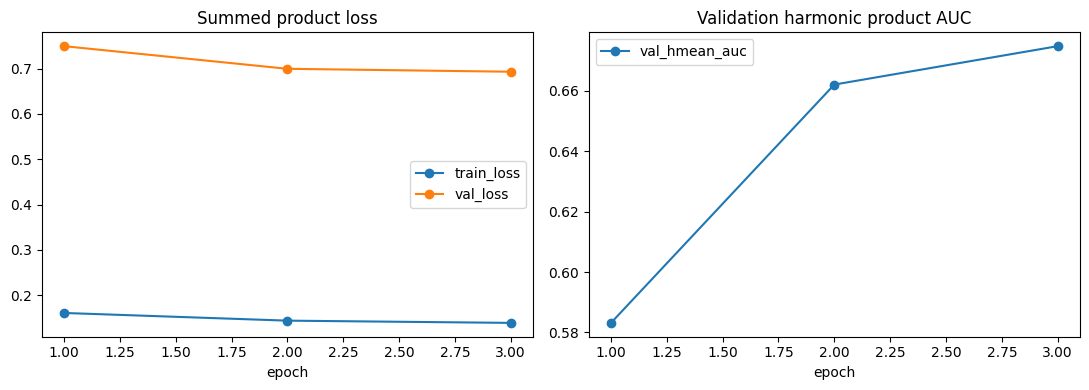

In [447]:
history = train_model(
    model, loaders['train'], loaders["valid"], EPOCHS, "main"
)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
history.plot(x="epoch", y=["train_loss", "val_loss"], marker="o",
             ax=axes[0], title="Summed product loss")
history.plot(x="epoch", y="val_hmean_auc", marker="o", ax=axes[1],
             title="Validation harmonic product AUC")
plt.tight_layout()


## Оценивание качества



In [448]:
features = pd.read_parquet("/kaggle/input/datasets/ahm352/t-intensive-features")

In [449]:
features

,app_id,product,COUNT(transactions),MAX(transactions.amnt),MAX(transactions.days_before),MAX(transactions.hour_diff),MAX(transactions.transaction_number),MEAN(transactions.amnt),MEAN(transactions.days_before),MEAN(transactions.hour_diff),...,STD(transactions.amnt),STD(transactions.days_before),STD(transactions.hour_diff),STD(transactions.transaction_number),SUM(transactions.amnt),SUM(transactions.days_before),SUM(transactions.hour_diff),SUM(transactions.transaction_number),flag,split
0,2,1,229,0.496822,351.0,875.0,229.0,0.306107,171.196507,36.655022,...,0.087890,96.796770,84.381177,66.250786,70.098407,39204.0,8394.0,26335.0,0,valid
1,5,1,90,0.594620,352.0,1943.0,90.0,0.401968,126.333333,91.955556,...,0.096075,105.088299,213.870323,26.124701,36.177086,11370.0,8276.0,4095.0,0,valid
2,6,1,260,0.686218,359.0,455.0,260.0,0.413805,202.861538,32.984615,...,0.106790,90.061048,83.360221,75.199734,107.589377,52744.0,8576.0,33930.0,0,train
3,7,0,91,0.476811,359.0,671.0,91.0,0.305449,157.219780,93.604396,...,0.091558,102.827342,157.927190,26.413380,27.795857,14307.0,8518.0,4186.0,0,test
4,8,2,26,0.539584,79.0,462.0,26.0,0.383976,41.846154,64.384615,...,0.081964,24.556372,125.261032,7.648529,9.983374,1088.0,1674.0,351.0,0,train
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
599995,1003044,1,260,0.638027,359.0,969.0,260.0,0.311101,214.230769,31.030769,...,0.097321,92.287451,93.914562,75.199734,80.886324,55700.0,8068.0,33930.0,0,train
599996,1003045,1,55,0.588211,344.0,843.0,55.0,0.451358,206.600000,146.400000,...,0.076019,95.496674,238.910536,16.020820,24.824672,11363.0,8052.0,1540.0,0,train
599997,1003047,0,260,0.661614,359.0,370.0,260.0,0.440434,185.080769,32.896154,...,0.099036,98.999967,58.307208,75.199734,114.512897,48121.0,8553.0,33930.0,0,train
599998,1003048,1,219,0.684931,359.0,1245.0,219.0,0.420723,121.292237,39.246575,...,0.103740,106.029408,118.453155,63.364028,92.138302,26563.0,8595.0,24090.0,0,valid


In [450]:
test_mask = features['split'] == 'test'

In [451]:
_, LSTM_FULL_HMEAN_AUC, lstm_y, lstm_p, lstm_ids, lstm_product = evaluate(
    model, loaders["test"], product_values
)
predictions = pd.DataFrame({"app_id": lstm_ids, "target": lstm_y,
                            "product": lstm_product, "probability": lstm_p})

boost_test_ids = set(features.loc[test_mask, "app_id"])

common = predictions[predictions["app_id"].isin(boost_test_ids)]

if len(common) != len(boost_test_ids):
    raise ValueError("Не все CatBoost test app_id найдены в LSTM shards")

boost_common = features.loc[test_mask, ["app_id", "product", "flag"]].copy()

same_test = boost_common.merge(
    common.rename(columns={"probability": "lstm_probability"}),
    on=["app_id", "product"], validate="one_to_one",
)

lstm_table = product_auc_table(
    same_test["target"], same_test["lstm_probability"], same_test["product"],
    product_values,
).rename(columns={"auc": "lstm_auc"}).drop(columns="n")

print(f"LSTM full-test harmonic product AUC: {LSTM_FULL_HMEAN_AUC:.6f}")

LSTM full-test harmonic product AUC: 0.678964


# EDA.
- Структура данных (обожаю последовательности, беру и обмазываюсь).
- Распределения и связи.
- Пропуски.

## Структура.

Так как бороться с шардами ради крупиц информации - это затея не очень приятная, то большую часть анализ проведём на агрегированных фичах для бустинга, которые появились на свет в результате работы featuretools, будем считать, что за нас посчитали уже интересные статистики, а мы из проанализируем.

Если упрощать всю нашу пляску с шардами, то у нас есть заявки, в каждой заявке есть $N_i$ транзакций, каждая транзакция для нас представляется вектором из $\mathbb{R}^{19}$, так как любая транзакция $t_j$ представляет собой вектор с 15 категориальными 4 непрерывными элементами, а тогда любая заявка может быть представлена в виде матрицы:
$$
A_i =
\begin{pmatrix}  & card\_type & city & \dots & transaction\_number \\
t_1 & & & \dots \\
& & &  \dots \\
t_{N_i} & & & \dots
\end{pmatrix}
$$
Правда на самом деле эта матрица дополняется нулевым паддингом для единообразия, но теоретически это выглядит именно так.

In [452]:
features = features.drop(columns = ['app_id', 'split'])
features.describe()

,product,COUNT(transactions),MAX(transactions.amnt),MAX(transactions.days_before),MAX(transactions.hour_diff),MAX(transactions.transaction_number),MEAN(transactions.amnt),MEAN(transactions.days_before),MEAN(transactions.hour_diff),MEAN(transactions.transaction_number),...,NUM_UNIQUE(transactions.weekofyear),STD(transactions.amnt),STD(transactions.days_before),STD(transactions.hour_diff),STD(transactions.transaction_number),SUM(transactions.amnt),SUM(transactions.days_before),SUM(transactions.hour_diff),SUM(transactions.transaction_number),flag
count,600000.000000,600000.0,600000.000000,600000.000000,600000.00000,600000.000000,600000.000000,600000.000000,600000.000000,600000.000000,...,600000.0,600000.000000,600000.000000,600000.000000,600000.000000,600000.000000,6.000000e+05,600000.000000,6.000000e+05,600000.000000
mean,0.868315,280.704058,0.602087,321.974140,702.79578,280.703480,0.380422,158.354085,95.264255,140.851592,...,33.797418,0.086849,89.719646,132.212173,81.175931,100.731773,4.585649e+04,7475.858623,8.751710e+04,0.027573
std,1.175202,309.774319,0.065567,70.606356,653.11317,309.772522,0.057090,47.707506,139.190135,154.885927,...,14.324255,0.022224,23.888682,159.024327,89.424012,110.802708,5.383004e+04,1803.716720,2.389796e+05,0.163747
min,0.000000,6.0,0.000000,1.000000,0.00000,6.000000,0.000000,1.000000,-0.166667,3.500000,...,1.0,0.000000,0.000000,0.277350,1.870829,0.000000,7.000000e+00,-1.000000,2.100000e+01,0.000000
25%,0.000000,66.0,0.558407,335.000000,333.00000,66.000000,0.339962,135.453301,19.574064,33.500000,...,22.0,0.074380,81.136086,37.825066,19.196354,25.789495,9.049000e+03,7458.000000,2.211000e+03,0.000000
50%,0.000000,177.0,0.601229,354.000000,542.00000,177.000000,0.370846,166.062708,40.130638,89.000000,...,36.0,0.085272,97.548865,80.714355,51.239633,64.497427,2.668800e+04,8341.000000,1.575300e+04,0.000000
75%,1.000000,388.0,0.646036,358.000000,838.00000,388.000000,0.412496,185.315789,100.893047,194.500000,...,47.0,0.097885,104.917126,171.014567,112.150197,137.242322,6.352400e+04,8528.000000,7.546600e+04,0.000000
max,4.000000,7288.0,0.965216,359.000000,8453.00000,7288.000000,0.764208,357.250000,1427.500000,3644.500000,...,52.0,0.314462,181.962267,3277.266341,2104.008714,2624.240617,1.277561e+06,11752.000000,2.656112e+07,1.000000


Отсюда сразу видно, что нас особо интересует распределение ```COUNT(transactions)```, потому что сильно маленькие заявки, возможно, убивают обучение из-за большого паддинга и малой информативности, очевидно распределение таргета ```flag```, ```SUM(transactions.amnt)``` как кандидата в наиболее информативную фичу, сюда же в целом все статистики, связанные с количеством, ```product```, так как, возможно, по какому-то продукту будет мало информации.

## Распределения и сопутствующая информация.

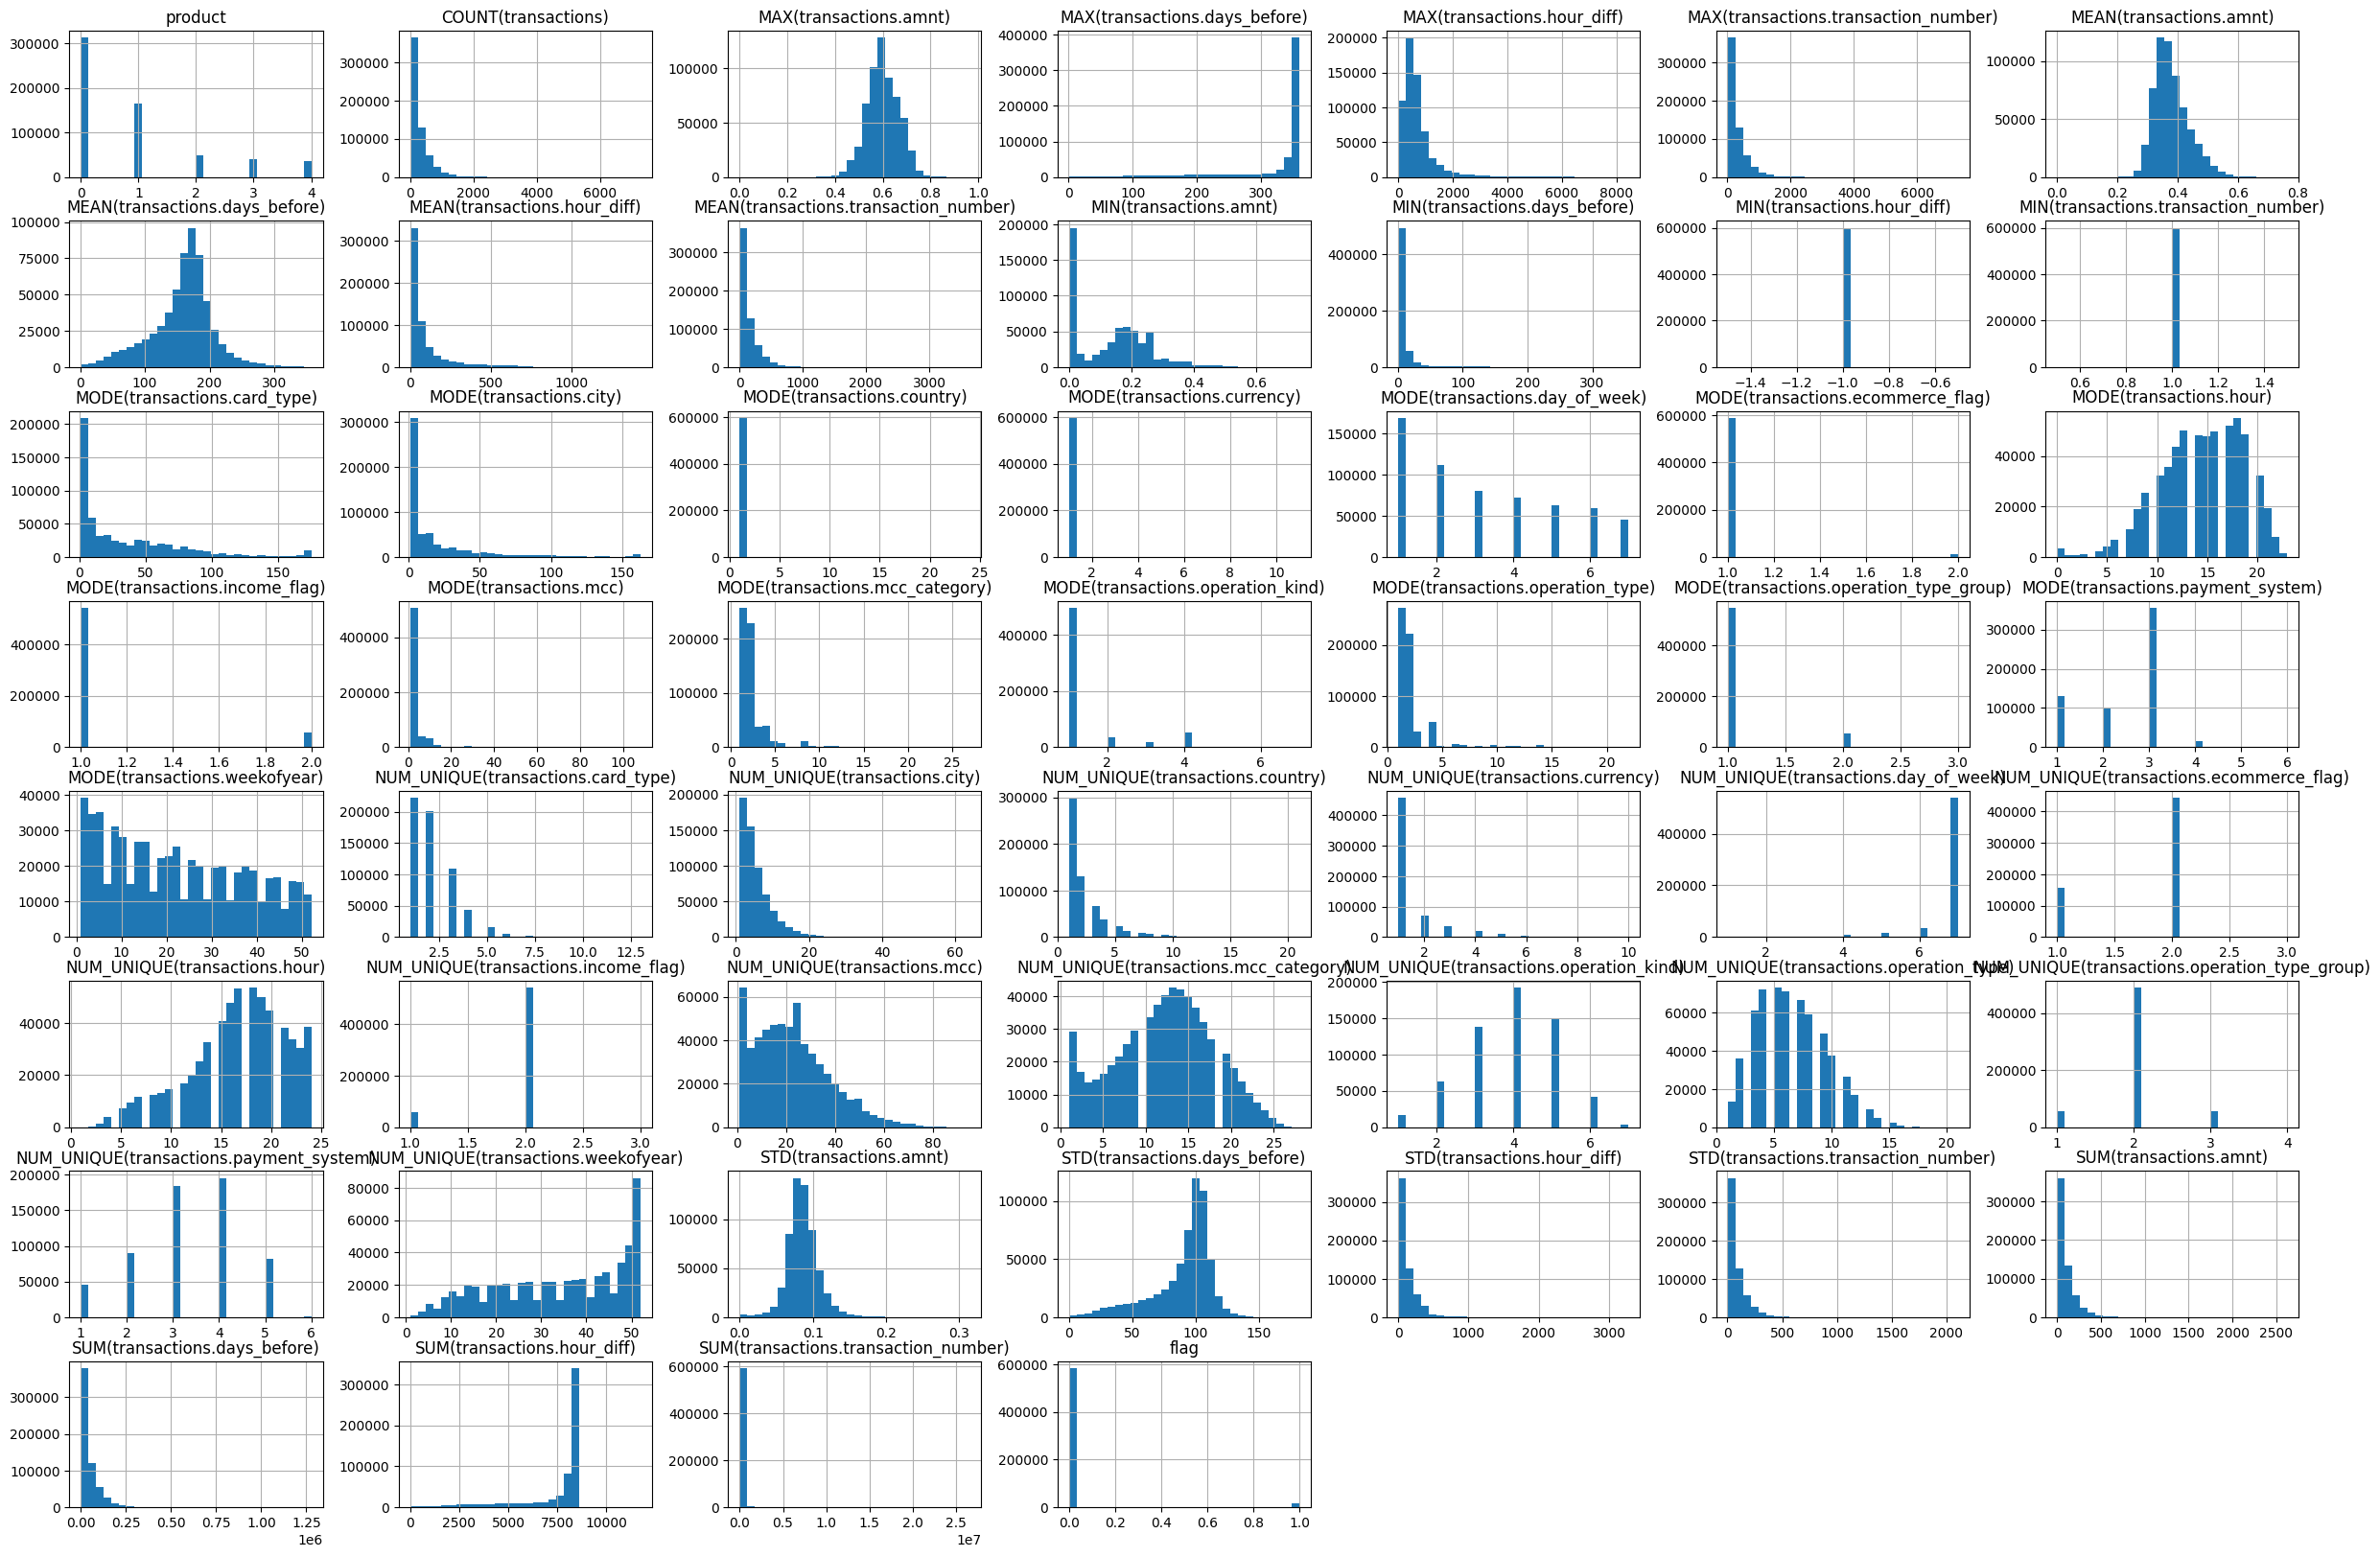

In [453]:
import seaborn as sns
import matplotlib.pyplot as plt


features.hist(figsize = (30, 20), bins = 30)
plt.show()

Видно, что у продукта есть некоторый дизбаланс, возможно, это как-то связано с дефолтом, например, что последний тип продукта - это суперэлитный кредит на хороших условиях для лояльных клиентов, соответственно, их возвраты будут по умолчанию чаще. А ещё огромный дизбаланс наблюдается у таргета. У ```count(transactions)``` что-то типа экспоненциального распределения, что вполне естественно, кажется, что если много качественных транзакций в заявке, то это доверенный клиент, который скорее всего вернёт деньги. Интересно, что ```max(transactions.day_before)``` в районе года, что говорит о том, что большинство заявок пришло от тех, кто давно с нами, но есть заявки и от тех, у кого почти не было транзакций - возможно, это подозрительно и указывает на фрод. Хотя ```mean(transactions.days_before)``` говорит о том, что в среднем между транзакциями наиболее вероятно окно в примерно 175 дней, а в целом распределение нормальное, то есть большие расстояния между транзакциями так же маловероятны, как и маленькие. У ```mode(transactions.card_type)``` что-то типа распределение Пуассона, может если клиент часто платит какой-то редкой картой, то он доверенный и едва ли не вернёт деньги, аналогично ```mode(transactions.mcc_category)```, может клиент платит в такой элитной сфере, что это почти гарантирует, что он вернёт деньги. Аналогично работают ```num_unique(t.card_type)```, ```num_unique(t.city)```, ```num_unique(t.county)``` (распределение которых похоже на распределение Пуассона), если в заявке разные типа карт, разные города и разные страны, то, наверное, клиент зажиточный, поэтому с большей вероятностью отдаст долг, хотя может и наборот, что он скрывается по городам и странам, и это будет фрод. В остальном видно, что данные уже стандартизованы и во многом распределения совпадают, поэтому большой работы с данными проводить не придётся.

## Корреляции.

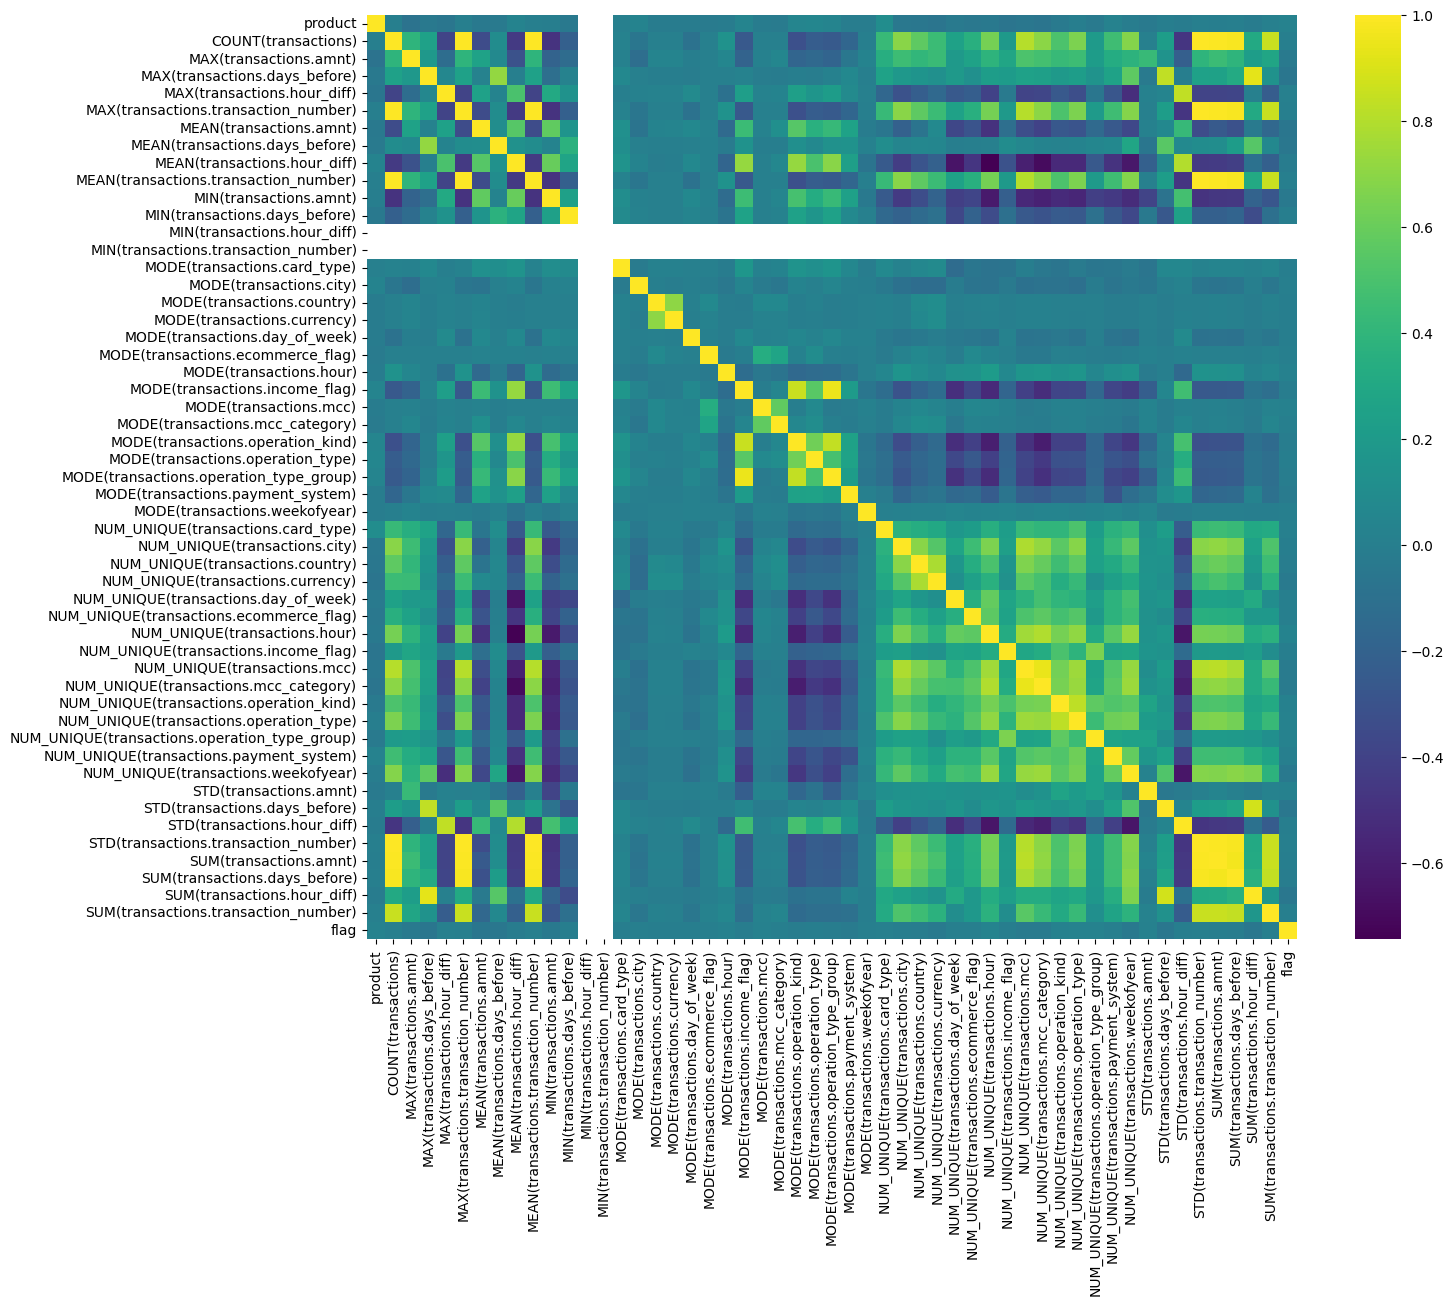

In [454]:
plt.figure(figsize = (15, 12))
sns.heatmap(features.corr(), cmap = 'viridis')
plt.show()


В целом тут ничего необычного: то, что должно коррелирует, коррелирует.

## Пропуски.

In [455]:
for split in ['train', 'test', 'valid']:
    paths = shard_paths(split)
    all_ok = True
    for path in paths:
        with np.load(path, allow_pickle=False) as data:
            for key in REQUIRED_SHARD_KEYS:
                arr = data[key]
                if np.isnan(arr).any():
                    all_ok = False
                if not np.isfinite(arr).all():
                    all_ok = False
    print(split, len(paths))
    if all_ok:
        print("Пропусков нет")
    else:
        print("Пропуски есть :(")


train 352
Пропусков нет
test 240
Пропусков нет
valid 240
Пропусков нет


# Эксперименты с данными.
- Один базовый.
- Один поинтереснее.

## Добавление существующих признаков.
Самое банальное, что мы можем сделать, это добавить остальные признаки в модель, так как в семинаре, видимо, специально оставили такое явное пространство для манёвра,используя только 5 фичей из 19 (да и даже в комментариях в коде выше было указано, что остальные фичи для домашки), а кто мы такие, чтобы этим не воспользоваться. Тем более, что данные уже приведены в комфортный для работы вид, а для нейронок обычно действует правило, что чем больше данных мы имеем, тем лучше её результат. Итак, **гипотеза:** докидывания всех остальных фичей даёт красивый прирост.

In [456]:
print(STORED_CAT_COLS, STORED_CONT_COLS)

CAT_COLS = STORED_CAT_COLS
CONT_COLS = STORED_CONT_COLS

missing = (set(CAT_COLS) - set(STORED_CAT_COLS)) | (
    set(CONT_COLS) - set(STORED_CONT_COLS)
)

if missing:
    raise ValueError(f"Baseline-колонки отсутствуют в Dataset: {sorted(missing)}")

CAT_INDICES = np.asarray([STORED_CAT_COLS.index(c) for c in CAT_COLS])
CONT_INDICES = np.asarray([STORED_CONT_COLS.index(c) for c in CONT_COLS])

vocab_specs = preprocessing["vocabularies"]

STORED_VOCAB_SIZES = {
    column: int(vocab_specs[column]["size"]) for column in STORED_CAT_COLS
}

VOCAB_SIZES = {column: STORED_VOCAB_SIZES[column] for column in CAT_COLS}

model = MultiHeadLSTM(
    VOCAB_SIZES, len(CONT_COLS), len(product_values)
).to(device)

model

['currency', 'operation_kind', 'card_type', 'operation_type', 'operation_type_group', 'ecommerce_flag', 'payment_system', 'income_flag', 'mcc', 'country', 'city', 'mcc_category', 'day_of_week', 'hour', 'weekofyear'] ['amnt', 'days_before', 'hour_diff', 'transaction_number']


MultiHeadLSTM(
  (embeddings): ModuleList(
    (0): Embedding(13, 12, padding_idx=0)
    (1): Embedding(9, 12, padding_idx=0)
    (2): Embedding(175, 12, padding_idx=0)
    (3): Embedding(24, 12, padding_idx=0)
    (4): Embedding(6, 12, padding_idx=0)
    (5): Embedding(5, 12, padding_idx=0)
    (6): Embedding(9, 12, padding_idx=0)
    (7): Embedding(5, 12, padding_idx=0)
    (8): Embedding(110, 12, padding_idx=0)
    (9): Embedding(26, 12, padding_idx=0)
    (10): Embedding(165, 12, padding_idx=0)
    (11): Embedding(30, 12, padding_idx=0)
    (12): Embedding(9, 12, padding_idx=0)
    (13): Embedding(26, 12, padding_idx=0)
    (14): Embedding(54, 12, padding_idx=0)
  )
  (encoder): LSTM(184, 64, batch_first=True)
  (dropout): Dropout(p=0.2, inplace=False)
  (heads): ModuleList(
    (0-4): 5 x Linear(in_features=64, out_features=1, bias=True)
  )
)

Epoch 1/3
Epoch 1/3: train_loss=0.1558, val_loss=0.7042, val_hmean_auc=0.641702
Epoch 2/3
Epoch 2/3: train_loss=0.1418, val_loss=0.6885, val_hmean_auc=0.691207
Epoch 3/3
Epoch 3/3: train_loss=0.1377, val_loss=0.6823, val_hmean_auc=0.700753


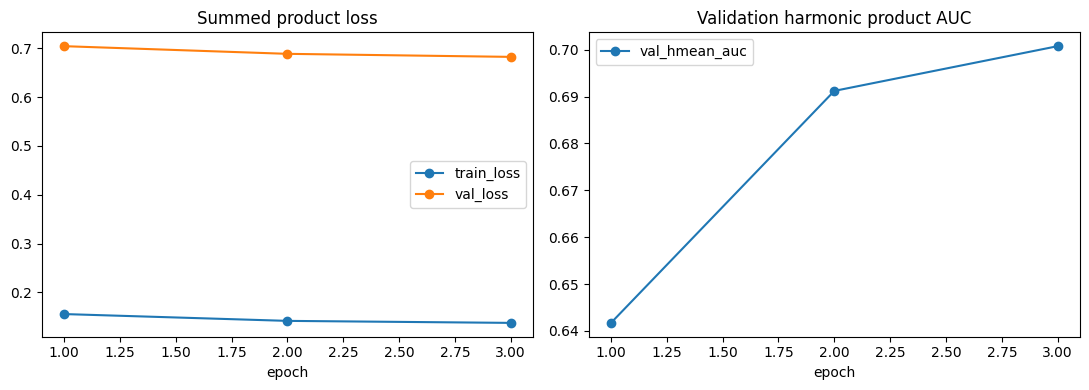

In [457]:
history = train_model(
    model, loaders['train'], loaders["valid"], EPOCHS, "main"
)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
history.plot(x="epoch", y=["train_loss", "val_loss"], marker="o",
             ax=axes[0], title="Summed product loss")
history.plot(x="epoch", y="val_hmean_auc", marker="o", ax=axes[1],
             title="Validation harmonic product AUC")
plt.tight_layout()


In [458]:
features = pd.read_parquet("/kaggle/input/datasets/ahm352/t-intensive-features")
_, LSTM_FULL_HMEAN_AUC, lstm_y, lstm_p, lstm_ids, lstm_product = evaluate(
    model, loaders["test"], product_values
)
predictions = pd.DataFrame({"app_id": lstm_ids, "target": lstm_y,
                            "product": lstm_product, "probability": lstm_p})

boost_test_ids = set(features.loc[test_mask, "app_id"])

common = predictions[predictions["app_id"].isin(boost_test_ids)]

if len(common) != len(boost_test_ids):
    raise ValueError("Не все CatBoost test app_id найдены в LSTM shards")

boost_common = features.loc[test_mask, ["app_id", "product", "flag"]].copy()

same_test = boost_common.merge(
    common.rename(columns={"probability": "lstm_probability"}),
    on=["app_id", "product"], validate="one_to_one",
)

lstm_table = product_auc_table(
    same_test["target"], same_test["lstm_probability"], same_test["product"],
    product_values,
).rename(columns={"auc": "lstm_auc"}).drop(columns="n")

print(f"LSTM full-test harmonic product AUC: {LSTM_FULL_HMEAN_AUC:.6f}")

LSTM full-test harmonic product AUC: 0.702954


**Выводы:** Джекпот! Простое действите, а мы уже улучшили метрику на $\approx 0.025$ относительного нашего бейзлайна, но до бустинга ещё не хватает $\approx 0.016$, но гипотеза подтвердилась. Причём, во-первых, время обучения на 3 эпохах не выросло существенно, во-вторых, переобучения от такого действия не случилось, если судить визуально по графикам. 

## Кто по странам гонял, тот ~~в цирке не смеётся~~ деньги не отдаст (или отдаст?..).
Как мы помним, в ходе EDA мы получили некоторую интересную информацию о наших данных, например, чем чем больше стран/городов есть в транзакциях, тем меньше вероятность такого события. Иными словами, возможно, мы сможем помочь нашей модели, если будем передавать флажки редких событий, например $\mathbb{I}(count(t.city) > 10)$, потому что в случае линейной модели это бы дало эффект, проверим наличия этого эффекта на нашей модели. Кроме того, будем передавать не только флажки, но и другие интересные статистики: количество транзакций, среднеее количество дней между транзакциями, количество городов, стран, типов оперций (да, вместе с флажками) и прочие. Здесь есть два подхода, как это лучше реализовать: отдельный вектор со всеми статистиками, информация с которого потом перемешается с выходом лстм либо каждый вектор в последовательности дополнить глобальным смыслом. Так как у нас тут эксперименты с данными, а не архитектурой, то будем придерживаться второго подхода, тем более, что добавлять глобальные связи в RNN - это хорошо. А ещё все эти фичи уже были агрегированы за нас, поэтому это не будет какой-то невероятно сложной задачи пробежаться по шардам и собрать всё это. Итак, **гипотеза:** расширение векторов транзакций глобальной информацией по заявке приведёт к увеличению качества. 
Добавляемые признаки:
- $\mathbb{I}(num\_unique(t.country) > 5)$
- $\mathbb{I}(num\_unique(t.city) > 10)$
- $\mathbb{I}(num\_unique(t.card\_type) > 4)$
<div align = 'center'> 
((Границы для всего здесь подбирались исходя из EDA, значения статистики больше порога становятся настолько маловероятны, что нам становится интересна их природа))
</div>
- count(transactions) (больше качестенных транзакций => больше доверия, больше странных => фрод).
- mean(t.days_before), std(t.days_before), max(t.days_before) (больше расстояние => давно с нами и больше доверия либо кризис и больше вероятность дефолта).
- mean(t.hours_diff) (может много мелких странных транзакций).
- num_unique(t.country), num_unique(t.city), num_unique(t.cardtype), num_unique(t.mcc_category), num_unique(t.operation_type).
- mean(t.amnt), std(t.amnt), sum(t.amnt) (кажется, самая информативная фича, дающая понимание про стабильность заявителя).

In [459]:
AGGR_COLS = [
    'COUNT(transactions)',
    'MEAN(transactions.days_before)',
    'STD(transactions.days_before)',
    'MAX(transactions.days_before)',
    'MEAN(transactions.hour_diff)',
    'NUM_UNIQUE(transactions.country)',
    'NUM_UNIQUE(transactions.city)',
    'NUM_UNIQUE(transactions.card_type)',
    'NUM_UNIQUE(transactions.mcc_category)',
    'NUM_UNIQUE(transactions.operation_type)',
    'MEAN(transactions.amnt)',
    'STD(transactions.amnt)',
    'SUM(transactions.amnt)',
]

features = pd.read_parquet("/kaggle/input/datasets/ahm352/t-intensive-features")
features[AGGR_COLS].head()

,COUNT(transactions),MEAN(transactions.days_before),STD(transactions.days_before),MAX(transactions.days_before),MEAN(transactions.hour_diff),NUM_UNIQUE(transactions.country),NUM_UNIQUE(transactions.city),NUM_UNIQUE(transactions.card_type),NUM_UNIQUE(transactions.mcc_category),NUM_UNIQUE(transactions.operation_type),MEAN(transactions.amnt),STD(transactions.amnt),SUM(transactions.amnt)
0,229,171.196507,96.796770,351.0,36.655022,2,8,1,9,10,0.306107,0.087890,70.098407
1,90,126.333333,105.088299,352.0,91.955556,2,4,2,10,3,0.401968,0.096075,36.177086
2,260,202.861538,90.061048,359.0,32.984615,6,6,6,19,9,0.413805,0.106790,107.589377
3,91,157.219780,102.827342,359.0,93.604396,2,5,1,14,6,0.305449,0.091558,27.795857
4,26,41.846154,24.556372,79.0,64.384615,1,4,1,5,3,0.383976,0.081964,9.983374


In [460]:
from sklearn.preprocessing import StandardScaler

train_app_ids = set()
for path in shard_paths('train'):
    with np.load(path, allow_pickle=False) as data:
        train_app_ids.update(data['app_id'].tolist())

train_mask = features['app_id'].isin(train_app_ids)
scaler = StandardScaler()
scaler.fit(features.loc[train_mask, AGGR_COLS])


StandardScaler()

In [461]:
features_subset = features[['app_id', 'split'] + AGGR_COLS].copy()
scaled_numeric = scaler.transform(features_subset[AGGR_COLS])

flags = np.column_stack([
    (features_subset[AGGR_COLS[2]].values > 5).astype(np.float32),
    (features_subset[AGGR_COLS[3]].values > 10).astype(np.float32),
    (features_subset[AGGR_COLS[4]].values > 4).astype(np.float32)
])

all_features = np.concatenate([scaled_numeric, flags], axis=1)

global_features_by_split = {}
for split_name in ['train', 'valid', 'test']:
    mask = features_subset['split'] == split_name
    split_app_ids = features_subset.loc[mask, 'app_id'].values
    split_features = all_features[mask]
    global_features_by_split[split_name] = dict(zip(split_app_ids, split_features))



In [462]:
class NpzSequenceDataset(IterableDataset):
    def __init__(self, files, global_features, shuffle=False, seed=SEED):
        self.files = list(files)
        self.global_features = global_features
        self.shuffle, self.seed, self.epoch = shuffle, seed, 0

    def __iter__(self):
        rng = np.random.default_rng(self.seed + self.epoch)
        files = list(self.files)
        if self.shuffle:
            rng.shuffle(files)
            self.epoch += 1
        for path in files:
            with np.load(path, allow_pickle=False) as archive:
                data = {key: archive[key] for key in REQUIRED_SHARD_KEYS}
            order = np.arange(len(data["lengths"]))
            if self.shuffle:
                rng.shuffle(order)
            for index in order:
                start, stop = data["offsets"][index:index + 2]
                cats = data["cats"][start:stop][:, CAT_INDICES]
                cont = data["cont"][start:stop][:, CONT_INDICES]
                
                app_id = int(data['app_id'][index])
                
                global_info = self.global_features[app_id]
                global_info_broadcasted = np.tile(global_info, (cont.shape[0], 1))
                cont_global = np.concatenate([cont, global_info_broadcasted], axis=1)
                
                yield (torch.from_numpy(cats).long(), torch.from_numpy(cont_global).float(),
                       int(data["lengths"][index]), float(data["target"][index]),
                       int(data["product_idx"][index]), int(data["app_id"][index]))

In [463]:
loaders = {}
for split_name in ["train", "valid", "test"]:
    dataset = NpzSequenceDataset(
        shard_paths(split_name),
        global_features=global_features_by_split[split_name],
        shuffle=(split_name == "train"),
    )
    loaders[split_name] = DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        collate_fn=collate,
        pin_memory=(device.type == "cuda")
    )

In [464]:
n_cont = len(CONT_COLS) + len(AGGR_COLS) + 3

model = MultiHeadLSTM(
    VOCAB_SIZES, n_cont, len(product_values)
).to(device)

model, n_cont

(MultiHeadLSTM(
   (embeddings): ModuleList(
     (0): Embedding(13, 12, padding_idx=0)
     (1): Embedding(9, 12, padding_idx=0)
     (2): Embedding(175, 12, padding_idx=0)
     (3): Embedding(24, 12, padding_idx=0)
     (4): Embedding(6, 12, padding_idx=0)
     (5): Embedding(5, 12, padding_idx=0)
     (6): Embedding(9, 12, padding_idx=0)
     (7): Embedding(5, 12, padding_idx=0)
     (8): Embedding(110, 12, padding_idx=0)
     (9): Embedding(26, 12, padding_idx=0)
     (10): Embedding(165, 12, padding_idx=0)
     (11): Embedding(30, 12, padding_idx=0)
     (12): Embedding(9, 12, padding_idx=0)
     (13): Embedding(26, 12, padding_idx=0)
     (14): Embedding(54, 12, padding_idx=0)
   )
   (encoder): LSTM(200, 64, batch_first=True)
   (dropout): Dropout(p=0.2, inplace=False)
   (heads): ModuleList(
     (0-4): 5 x Linear(in_features=64, out_features=1, bias=True)
   )
 ),
 20)

Epoch 1/3
Epoch 1/3: train_loss=0.1549, val_loss=0.7007, val_hmean_auc=0.671011
Epoch 2/3
Epoch 2/3: train_loss=0.1384, val_loss=0.6866, val_hmean_auc=0.685709
Epoch 3/3
Epoch 3/3: train_loss=0.1359, val_loss=0.6854, val_hmean_auc=0.695742


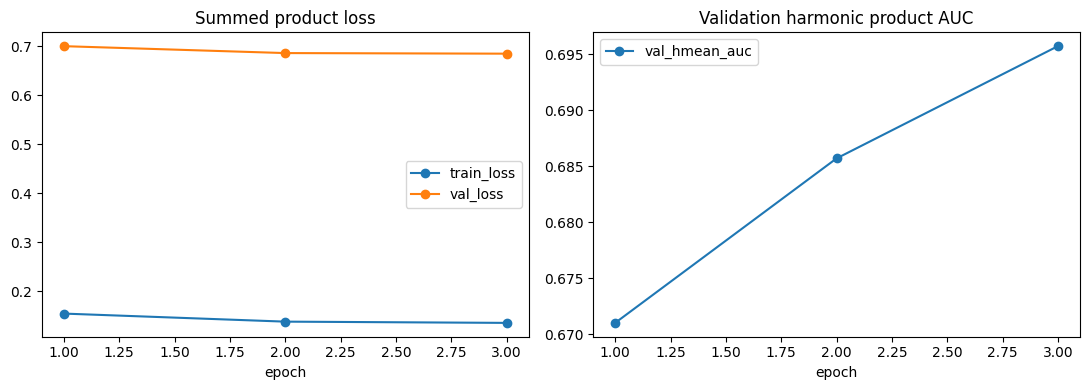

In [465]:
history = train_model(
    model, loaders['train'], loaders["valid"], EPOCHS, "main"
)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
history.plot(x="epoch", y=["train_loss", "val_loss"], marker="o",
             ax=axes[0], title="Summed product loss")
history.plot(x="epoch", y="val_hmean_auc", marker="o", ax=axes[1],
             title="Validation harmonic product AUC")
plt.tight_layout()


In [466]:
features = pd.read_parquet("/kaggle/input/datasets/ahm352/t-intensive-features")
_, LSTM_FULL_HMEAN_AUC, lstm_y, lstm_p, lstm_ids, lstm_product = evaluate(
    model, loaders["test"], product_values
)
predictions = pd.DataFrame({"app_id": lstm_ids, "target": lstm_y,
                            "product": lstm_product, "probability": lstm_p})

boost_test_ids = set(features.loc[test_mask, "app_id"])

common = predictions[predictions["app_id"].isin(boost_test_ids)]

if len(common) != len(boost_test_ids):
    raise ValueError("Не все CatBoost test app_id найдены в LSTM shards")

boost_common = features.loc[test_mask, ["app_id", "product", "flag"]].copy()

same_test = boost_common.merge(
    common.rename(columns={"probability": "lstm_probability"}),
    on=["app_id", "product"], validate="one_to_one",
)

lstm_table = product_auc_table(
    same_test["target"], same_test["lstm_probability"], same_test["product"],
    product_values,
).rename(columns={"auc": "lstm_auc"}).drop(columns="n")

print(f"LSTM full-test harmonic product AUC: {LSTM_FULL_HMEAN_AUC:.6f}")

LSTM full-test harmonic product AUC: 0.713837


**Вывод**: гипотеза подтвердилась, так как метрика выросла до $\approx 0.71$, что на $\approx 0.009$ больше прошлого результата в $0.702954$, соответственно, это больше бейзлайна на $\approx 0.033$ и меньше цели на $\approx 0.0082$. Однако здесь важно учитывать, что перед подачей в модель данные нужно стандартизировать, иначе никакого прироста не будет, связано это с тем, что, во-первых, все изначальные фичи стандартизованы, а во-вторых, LSTM сильно завязана на линейных слоях, а тогда если не приводить всё в единый масштаб, то мы будем какие-то фичи незаслуженно завышать/занижать.

# Эксперименты с архитектурой.
- Два базовых.

## Не меняем саму архитектуру, но меняем её параметры.
Начнём с чего-то максимально простого: вместо того, чтобы сразу перелопачивать всю модель, менять слои и блоки, мы попробуем сначала выжать максимум из нашей базовой модели, а для этого мы, во-первых, увеличим размерность эмбеддингов, потому что чем больше вектор, тем больше смысла он может сохранить, во-вторых, исходя из такой же логики мы увеличим размерность скрытого состояния. Из EDA мы знаем, что у большинства заявок количество транзакций меньше тысячи, а на самом деле даже меньше 500, то есть в нашем случае наши последовательности не такие длинные, а значит, что LSTM может хорошо себя на них показать, просто нужно дать ему больше возможности работать с длинными последовательностями, увеличив его ёмкость. Итак, **гипотеза:** увеличение hidden_state и emb_dim приведёт к улучшению качества модели.

In [467]:
class LargeMultiHeadLSTM(nn.Module):
    """Shared transaction encoder with one binary head per product."""
    def __init__(self, vocab_sizes, n_cont, n_products, emb_dim=20, hidden=128):
        """Construct embeddings, shared LSTM and product heads.
        Parameters
        ----------
        vocab_sizes : dict[str, int]
            Embedding sizes including PAD=0 and UNK=1.
        n_cont, n_products : int
            Continuous feature count and number of heads.
        emb_dim, hidden : int
            Embedding and LSTM hidden widths.
        """
        super().__init__()
        self.embeddings = nn.ModuleList([
            nn.Embedding(vocab_sizes[name], emb_dim, padding_idx=0)
            for name in CAT_COLS
        ])
        width = emb_dim * len(CAT_COLS) + n_cont
        self.encoder = nn.LSTM(width, hidden, batch_first=True)
        self.dropout = nn.Dropout(0.2)
        self.heads = nn.ModuleList([nn.Linear(hidden, 1)
                                    for _ in range(n_products)])
    def forward(self, cats, cont, lengths, product):
        """Encode histories and return each row's selected-head logit.

        Batch-first inputs are packed, so padding cannot alter the final
        shared state. The returned tensor has shape ``(B,)``.
        """
        embedded = [layer(cats[:, :, index])
                    for index, layer in enumerate(self.embeddings)]
        sequence = torch.cat([*embedded, cont], dim=-1)
        packed = pack_padded_sequence(
            sequence, lengths.cpu(), batch_first=True, enforce_sorted=False
        )
        _, (hidden, _) = self.encoder(packed)
        logits = torch.cat([head(self.dropout(hidden[-1]))
                            for head in self.heads], dim=1)
        return logits.gather(1, product[:, None]).squeeze(1)

In [468]:
n_cont = len(CONT_COLS) + len(AGGR_COLS) + 3

model = LargeMultiHeadLSTM(
    VOCAB_SIZES, n_cont, len(product_values)
).to(device)

model, n_cont

(LargeMultiHeadLSTM(
   (embeddings): ModuleList(
     (0): Embedding(13, 20, padding_idx=0)
     (1): Embedding(9, 20, padding_idx=0)
     (2): Embedding(175, 20, padding_idx=0)
     (3): Embedding(24, 20, padding_idx=0)
     (4): Embedding(6, 20, padding_idx=0)
     (5): Embedding(5, 20, padding_idx=0)
     (6): Embedding(9, 20, padding_idx=0)
     (7): Embedding(5, 20, padding_idx=0)
     (8): Embedding(110, 20, padding_idx=0)
     (9): Embedding(26, 20, padding_idx=0)
     (10): Embedding(165, 20, padding_idx=0)
     (11): Embedding(30, 20, padding_idx=0)
     (12): Embedding(9, 20, padding_idx=0)
     (13): Embedding(26, 20, padding_idx=0)
     (14): Embedding(54, 20, padding_idx=0)
   )
   (encoder): LSTM(320, 128, batch_first=True)
   (dropout): Dropout(p=0.2, inplace=False)
   (heads): ModuleList(
     (0-4): 5 x Linear(in_features=128, out_features=1, bias=True)
   )
 ),
 20)

Epoch 1/3
Epoch 1/3: train_loss=0.1534, val_loss=0.7254, val_hmean_auc=0.651095
Epoch 2/3
Epoch 2/3: train_loss=0.1404, val_loss=0.6941, val_hmean_auc=0.665833
Epoch 3/3
Epoch 3/3: train_loss=0.1377, val_loss=0.6940, val_hmean_auc=0.682780


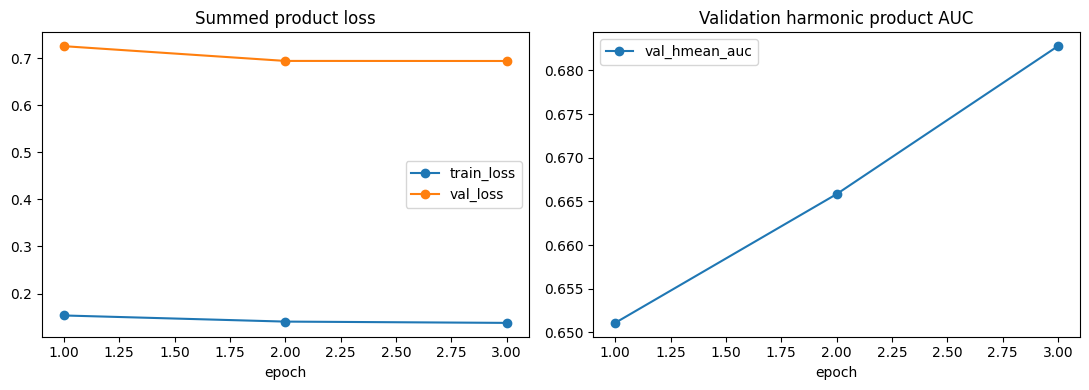

In [469]:
loaders = {}
for split_name in ["train", "valid", "test"]:
    dataset = NpzSequenceDataset(
        shard_paths(split_name),
        global_features=global_features_by_split[split_name],
        shuffle=(split_name == "train"),
    )
    loaders[split_name] = DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        collate_fn=collate,
        pin_memory=(device.type == "cuda")
    )
    
history = train_model(
    model, loaders['train'], loaders["valid"], EPOCHS, "main"
)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
history.plot(x="epoch", y=["train_loss", "val_loss"], marker="o",
             ax=axes[0], title="Summed product loss")
history.plot(x="epoch", y="val_hmean_auc", marker="o", ax=axes[1],
             title="Validation harmonic product AUC")
plt.tight_layout()


In [470]:
features = pd.read_parquet("/kaggle/input/datasets/ahm352/t-intensive-features")
_, LSTM_FULL_HMEAN_AUC, lstm_y, lstm_p, lstm_ids, lstm_product = evaluate(
    model, loaders["test"], product_values
)
predictions = pd.DataFrame({"app_id": lstm_ids, "target": lstm_y,
                            "product": lstm_product, "probability": lstm_p})

boost_test_ids = set(features.loc[test_mask, "app_id"])

common = predictions[predictions["app_id"].isin(boost_test_ids)]

if len(common) != len(boost_test_ids):
    raise ValueError("Не все CatBoost test app_id найдены в LSTM shards")

boost_common = features.loc[test_mask, ["app_id", "product", "flag"]].copy()

same_test = boost_common.merge(
    common.rename(columns={"probability": "lstm_probability"}),
    on=["app_id", "product"], validate="one_to_one",
)

lstm_table = product_auc_table(
    same_test["target"], same_test["lstm_probability"], same_test["product"],
    product_values,
).rename(columns={"auc": "lstm_auc"}).drop(columns="n")

print(f"LSTM full-test harmonic product AUC: {LSTM_FULL_HMEAN_AUC:.6f}")

LSTM full-test harmonic product AUC: 0.693590


**Вывод:** гипотеза не оправдалась, так как метрика только упала из-за этого, хотя на графике видно, что функция потерь стабильно падает, а метрика стабильно растёт за 3 эпохи, так что вполне возможно, что раз мы увеличили ёмкость модели, то необходимо увеличить количество эпох обучения, так как сейчас модель не успевает сойтись за это количество. Возможно нужно будет уменьшить при это learning_rate, чтобы модель не крутилась вокруг экстремума, но это всё будет проверяться в другом разделе.

## БОЛЬШЕ СЛОЁВ!!
Ну, параметры исходной модели мы поменяли, но можно пойти дальше и сделать модель из двух LSTM слоёв. Это может быть хорошей идеей, так как многослойный лстм устроен как башенка, то есть на вход каждого i-блока из второго LSTM слоя будет приходить слева $h^{(2)}_{i-1}$ - скрытое состояние этого лстм-слоя и снизу $h^{(1)}_i$ - скрытое состояние с i-ого блока первого LSTM, то есть такая архитектура позволяет вычленять более сложную информацию, так как мы учитываем как и новую информацию, которую мы получаем на новом лстм блоке, так и базову информацию с нижних блоков, а так как у нас довольно разные данные, то это может быть очень кстати. Для этого есть некоторые предпосылки: во-первых, увеличение размерности скрытых состояний не привело к увеличению метрики, значит, возможно, мы достаточно информации упаковываем, но не можем её достаточно хорошо проанализировать из-за возможно сложных связей и мелкости нашей нейронки, во-вторых, прошлый эксперимент не привёл к переобучению, так что, возможно, модель просто слишком простая. Итак, **гипотеза**: усложенение нейросети в виде увеличения количества LSTM слоёв должно привести к улучшению метрики.

In [471]:
class ExtraLargeMultiHeadLSTM(nn.Module):
    """Shared transaction encoder with one binary head per product."""
    def __init__(self, vocab_sizes, n_cont, n_products, emb_dim=20, hidden=128):
        """Construct embeddings, shared LSTM and product heads.
        Parameters
        ----------
        vocab_sizes : dict[str, int]
            Embedding sizes including PAD=0 and UNK=1.
        n_cont, n_products : int
            Continuous feature count and number of heads.
        emb_dim, hidden : int
            Embedding and LSTM hidden widths.
        """
        super().__init__()
        self.embeddings = nn.ModuleList([
            nn.Embedding(vocab_sizes[name], emb_dim, padding_idx=0)
            for name in CAT_COLS
        ])
        width = emb_dim * len(CAT_COLS) + n_cont
        self.encoder = nn.LSTM(width, hidden, num_layers = 2, dropout = 0.2, batch_first=True)
        self.dropout = nn.Dropout(0.2)
        self.heads = nn.ModuleList([nn.Linear(hidden, 1)
                                    for _ in range(n_products)])
    def forward(self, cats, cont, lengths, product):
        """Encode histories and return each row's selected-head logit.

        Batch-first inputs are packed, so padding cannot alter the final
        shared state. The returned tensor has shape ``(B,)``.
        """
        embedded = [layer(cats[:, :, index])
                    for index, layer in enumerate(self.embeddings)]
        sequence = torch.cat([*embedded, cont], dim=-1)
        packed = pack_padded_sequence(
            sequence, lengths.cpu(), batch_first=True, enforce_sorted=False
        )
        _, (hidden, _) = self.encoder(packed)
        logits = torch.cat([head(self.dropout(hidden[-1]))
                            for head in self.heads], dim=1)
        return logits.gather(1, product[:, None]).squeeze(1)

In [472]:
n_cont = len(CONT_COLS) + len(AGGR_COLS) + 3

model = ExtraLargeMultiHeadLSTM(
    VOCAB_SIZES, n_cont, len(product_values)
).to(device)

model, n_cont

(ExtraLargeMultiHeadLSTM(
   (embeddings): ModuleList(
     (0): Embedding(13, 20, padding_idx=0)
     (1): Embedding(9, 20, padding_idx=0)
     (2): Embedding(175, 20, padding_idx=0)
     (3): Embedding(24, 20, padding_idx=0)
     (4): Embedding(6, 20, padding_idx=0)
     (5): Embedding(5, 20, padding_idx=0)
     (6): Embedding(9, 20, padding_idx=0)
     (7): Embedding(5, 20, padding_idx=0)
     (8): Embedding(110, 20, padding_idx=0)
     (9): Embedding(26, 20, padding_idx=0)
     (10): Embedding(165, 20, padding_idx=0)
     (11): Embedding(30, 20, padding_idx=0)
     (12): Embedding(9, 20, padding_idx=0)
     (13): Embedding(26, 20, padding_idx=0)
     (14): Embedding(54, 20, padding_idx=0)
   )
   (encoder): LSTM(320, 128, num_layers=2, batch_first=True, dropout=0.2)
   (dropout): Dropout(p=0.2, inplace=False)
   (heads): ModuleList(
     (0-4): 5 x Linear(in_features=128, out_features=1, bias=True)
   )
 ),
 20)

Epoch 1/3
Epoch 1/3: train_loss=0.1564, val_loss=0.7449, val_hmean_auc=0.646196
Epoch 2/3
Epoch 2/3: train_loss=0.1396, val_loss=0.6922, val_hmean_auc=0.681690
Epoch 3/3
Epoch 3/3: train_loss=0.1362, val_loss=0.6884, val_hmean_auc=0.694912


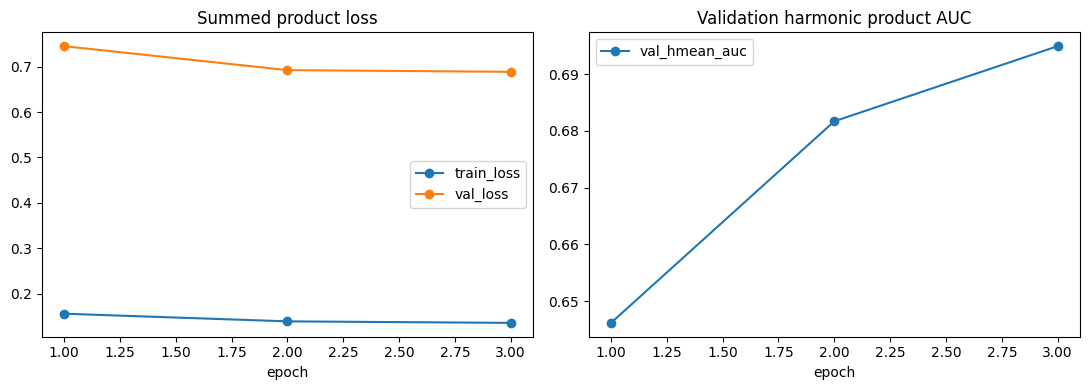

In [473]:
loaders = {}
for split_name in ["train", "valid", "test"]:
    dataset = NpzSequenceDataset(
        shard_paths(split_name),
        global_features=global_features_by_split[split_name],
        shuffle=(split_name == "train"),
    )
    loaders[split_name] = DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        collate_fn=collate,
        pin_memory=(device.type == "cuda")
    )
    
history = train_model(
    model, loaders['train'], loaders["valid"], EPOCHS, "main"
)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
history.plot(x="epoch", y=["train_loss", "val_loss"], marker="o",
             ax=axes[0], title="Summed product loss")
history.plot(x="epoch", y="val_hmean_auc", marker="o", ax=axes[1],
             title="Validation harmonic product AUC")
plt.tight_layout()


In [474]:
features = pd.read_parquet("/kaggle/input/datasets/ahm352/t-intensive-features")
_, LSTM_FULL_HMEAN_AUC, lstm_y, lstm_p, lstm_ids, lstm_product = evaluate(
    model, loaders["test"], product_values
)
predictions = pd.DataFrame({"app_id": lstm_ids, "target": lstm_y,
                            "product": lstm_product, "probability": lstm_p})

boost_test_ids = set(features.loc[test_mask, "app_id"])

common = predictions[predictions["app_id"].isin(boost_test_ids)]

if len(common) != len(boost_test_ids):
    raise ValueError("Не все CatBoost test app_id найдены в LSTM shards")

boost_common = features.loc[test_mask, ["app_id", "product", "flag"]].copy()

same_test = boost_common.merge(
    common.rename(columns={"probability": "lstm_probability"}),
    on=["app_id", "product"], validate="one_to_one",
)

lstm_table = product_auc_table(
    same_test["target"], same_test["lstm_probability"], same_test["product"],
    product_values,
).rename(columns={"auc": "lstm_auc"}).drop(columns="n")

print(f"LSTM full-test harmonic product AUC: {LSTM_FULL_HMEAN_AUC:.6f}")

LSTM full-test harmonic product AUC: 0.710859


**Вывод:** гипотеза не оправдалась ровно по той же причине: нам не хватает эпох, чтобы модель сошлась, что явно демонстрирует график. Уже на следующем этапе мы проверим, поможет ли нам увеличение эпох.

## Кручу-верчу, всю информацию собрать хочу!
Это естественное продолжение прошлого эксперимента, хотя этот скорее всего тоже недообучится, но это будет почвой для экспериментов с обучением. Сейчас у нас такая модель, которая обрабатывает $t_1, t_2, t_3, \dots$ последовательно в прямом обходе, то есть у нас нижний LSTM собирает общую информацию о последовательности $t_1, t_2, \dots$, затем второй слой уже с учётом базовой информации вытаскивает более сложну информацию, но всё о той же последовательност $t_1, t_2, t_3, \dots$. Мы уже собрали какой-то глобальный контекст, добавив в вектора статистики по всей заявке, но нам, возможно, интересна информацию о последовательности $t_N, t_{N-1}, \dots, t_1$, поэтому, возможно, будет круто сделать трёхслойную LSTM, в которой первый слой обходит последовательность прямо, второй в обратном порядке, третий снова прямо, тогда мы на третьем слое будем получать базовую информацию о этой транзакции и в прямом, и в обратном проходе, так ещё и какую-то сложную информацию в прямом проходе, единственное, что нужно быть аккуратными с переобучением в этом случае. Итак, **гипотеза:** трёхслойная LSTM с прямым, обратным и снова прямым обходом даст прирост в метрике.

In [475]:
class TripleLargeMultiHeadLSTM(nn.Module):
    """Shared transaction encoder with one binary head per product."""
    def __init__(self, vocab_sizes, n_cont, n_products, emb_dim=20, hidden=128):
        """Construct embeddings, shared LSTM and product heads.
        Parameters
        ----------
        vocab_sizes : dict[str, int]
            Embedding sizes including PAD=0 and UNK=1.
        n_cont, n_products : int
            Continuous feature count and number of heads.
        emb_dim, hidden : int
            Embedding and LSTM hidden widths.
        """
        super().__init__()
        self.embeddings = nn.ModuleList([
            nn.Embedding(vocab_sizes[name], emb_dim, padding_idx=0)
            for name in CAT_COLS
        ])
        width = emb_dim * len(CAT_COLS) + n_cont
        
        self.lstm1 = nn.LSTM(width, hidden, batch_first = True)
        self.lstm2 = nn.LSTM(hidden, hidden, batch_first = True)
        self.lstm3 = nn.LSTM(hidden, hidden, batch_first = True)
        
        self.dropout = nn.Dropout(0.2)
        self.heads = nn.ModuleList([nn.Linear(hidden, 1)
                                    for _ in range(n_products)])
        
    def forward(self, cats, cont, lengths, product):
        """Encode histories and return each row's selected-head logit.

        Batch-first inputs are packed, so padding cannot alter the final
        shared state. The returned tensor has shape ``(B,)``.
        """
        embedded = [layer(cats[:, :, index])
                    for index, layer in enumerate(self.embeddings)]
        sequence = torch.cat([*embedded, cont], dim=-1)

        device = sequence.device
        lengths = lengths.to(device)
        
        B, N = sequence.shape[:2]
        mask = torch.arange(N, device=device).unsqueeze(0) < lengths.unsqueeze(1)

        out, _ = self.lstm1(sequence)
        out = out * mask.unsqueeze(-1).float()
        out = self.dropout(out)

        rev_idx = torch.where(
            mask,
            lengths.unsqueeze(1) - 1 - torch.arange(N, device=device).unsqueeze(0),
            torch.arange(N, device=device).unsqueeze(0)
        )
        rev_idx = rev_idx.unsqueeze(-1).expand(-1, -1, out.size(-1))
        out = out.gather(1, rev_idx)

        out, _ = self.lstm2(out)
        out = out * mask.unsqueeze(-1).float()
        out = self.dropout(out)

        out = out.gather(1, rev_idx)

        out, (hidden, _) = self.lstm3(out)

        hidden = out[torch.arange(B, device=device), lengths - 1, :]
        hidden = self.dropout(hidden)

        logits = torch.cat([head(hidden) for head in self.heads], dim=1)
        return logits.gather(1, product[:, None]).squeeze(1)

In [476]:
n_cont = len(CONT_COLS) + len(AGGR_COLS) + 3

model = TripleLargeMultiHeadLSTM(
    VOCAB_SIZES, n_cont, len(product_values)
).to(device)

model, n_cont

(TripleLargeMultiHeadLSTM(
   (embeddings): ModuleList(
     (0): Embedding(13, 20, padding_idx=0)
     (1): Embedding(9, 20, padding_idx=0)
     (2): Embedding(175, 20, padding_idx=0)
     (3): Embedding(24, 20, padding_idx=0)
     (4): Embedding(6, 20, padding_idx=0)
     (5): Embedding(5, 20, padding_idx=0)
     (6): Embedding(9, 20, padding_idx=0)
     (7): Embedding(5, 20, padding_idx=0)
     (8): Embedding(110, 20, padding_idx=0)
     (9): Embedding(26, 20, padding_idx=0)
     (10): Embedding(165, 20, padding_idx=0)
     (11): Embedding(30, 20, padding_idx=0)
     (12): Embedding(9, 20, padding_idx=0)
     (13): Embedding(26, 20, padding_idx=0)
     (14): Embedding(54, 20, padding_idx=0)
   )
   (lstm1): LSTM(320, 128, batch_first=True)
   (lstm2): LSTM(128, 128, batch_first=True)
   (lstm3): LSTM(128, 128, batch_first=True)
   (dropout): Dropout(p=0.2, inplace=False)
   (heads): ModuleList(
     (0-4): 5 x Linear(in_features=128, out_features=1, bias=True)
   )
 ),
 20)

Epoch 1/3
Epoch 1/3: train_loss=0.1575, val_loss=0.7894, val_hmean_auc=0.616299
Epoch 2/3
Epoch 2/3: train_loss=0.1446, val_loss=0.6995, val_hmean_auc=0.665026
Epoch 3/3
Epoch 3/3: train_loss=0.1387, val_loss=0.6945, val_hmean_auc=0.685195


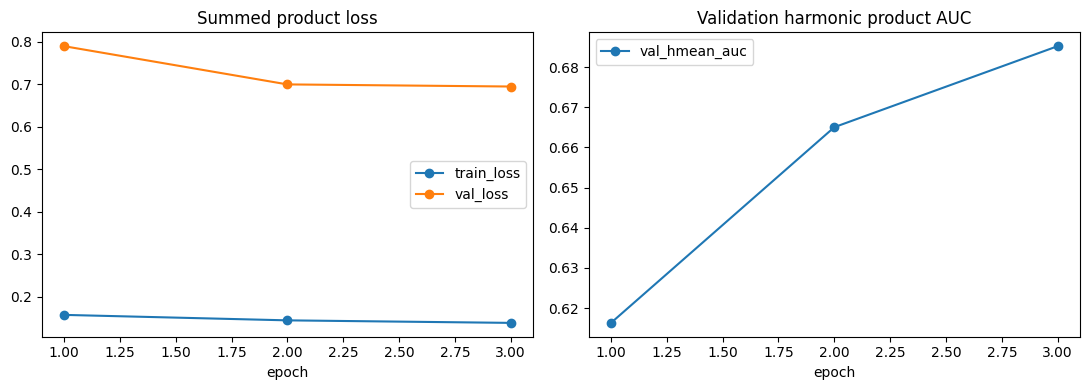

In [477]:
loaders = {}
for split_name in ["train", "valid", "test"]:
    dataset = NpzSequenceDataset(
        shard_paths(split_name),
        global_features=global_features_by_split[split_name],
        shuffle=(split_name == "train"),
    )
    loaders[split_name] = DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        collate_fn=collate,
        pin_memory=(device.type == "cuda")
    )
    
history = train_model(
    model, loaders['train'], loaders["valid"], EPOCHS, "main"
)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
history.plot(x="epoch", y=["train_loss", "val_loss"], marker="o",
             ax=axes[0], title="Summed product loss")
history.plot(x="epoch", y="val_hmean_auc", marker="o", ax=axes[1],
             title="Validation harmonic product AUC")
plt.tight_layout()


In [478]:
features = pd.read_parquet("/kaggle/input/datasets/ahm352/t-intensive-features")
_, LSTM_FULL_HMEAN_AUC, lstm_y, lstm_p, lstm_ids, lstm_product = evaluate(
    model, loaders["test"], product_values
)
predictions = pd.DataFrame({"app_id": lstm_ids, "target": lstm_y,
                            "product": lstm_product, "probability": lstm_p})

boost_test_ids = set(features.loc[test_mask, "app_id"])

common = predictions[predictions["app_id"].isin(boost_test_ids)]

if len(common) != len(boost_test_ids):
    raise ValueError("Не все CatBoost test app_id найдены в LSTM shards")

boost_common = features.loc[test_mask, ["app_id", "product", "flag"]].copy()

same_test = boost_common.merge(
    common.rename(columns={"probability": "lstm_probability"}),
    on=["app_id", "product"], validate="one_to_one",
)

lstm_table = product_auc_table(
    same_test["target"], same_test["lstm_probability"], same_test["product"],
    product_values,
).rename(columns={"auc": "lstm_auc"}).drop(columns="n")

print(f"LSTM full-test harmonic product AUC: {LSTM_FULL_HMEAN_AUC:.6f}")

LSTM full-test harmonic product AUC: 0.699754


**Вывод:** аналогичный, стабильный рост метрики вместе со стабильным падением функции потерь, для однозначного ответа нужно увеличивать количество эпох, на данном этапе гипотеза не оправдалась.

# Эксперименты
- Два базовейшийх.

## Дайте им немного времени...
Наконец мы дошли до того, чтобы попробовать самое банальное улучшение: уменьшение lr и увеличение количества эпох для двуслойной и трёхслойной LSTM, кажется, здесь всё понятно. Итак, **гипотеза:** уменьшение learning_rate вместе с увеличением количества эпох для многослойных LSTM дадут прирост метрики.

In [479]:
n_cont = len(CONT_COLS) + len(AGGR_COLS) + 3

model = ExtraLargeMultiHeadLSTM(
    VOCAB_SIZES, n_cont, len(product_values)
).to(device)

model, n_cont

(ExtraLargeMultiHeadLSTM(
   (embeddings): ModuleList(
     (0): Embedding(13, 20, padding_idx=0)
     (1): Embedding(9, 20, padding_idx=0)
     (2): Embedding(175, 20, padding_idx=0)
     (3): Embedding(24, 20, padding_idx=0)
     (4): Embedding(6, 20, padding_idx=0)
     (5): Embedding(5, 20, padding_idx=0)
     (6): Embedding(9, 20, padding_idx=0)
     (7): Embedding(5, 20, padding_idx=0)
     (8): Embedding(110, 20, padding_idx=0)
     (9): Embedding(26, 20, padding_idx=0)
     (10): Embedding(165, 20, padding_idx=0)
     (11): Embedding(30, 20, padding_idx=0)
     (12): Embedding(9, 20, padding_idx=0)
     (13): Embedding(26, 20, padding_idx=0)
     (14): Embedding(54, 20, padding_idx=0)
   )
   (encoder): LSTM(320, 128, num_layers=2, batch_first=True, dropout=0.2)
   (dropout): Dropout(p=0.2, inplace=False)
   (heads): ModuleList(
     (0-4): 5 x Linear(in_features=128, out_features=1, bias=True)
   )
 ),
 20)

Epoch 1/9
Epoch 1/9: train_loss=0.1789, val_loss=0.7070, val_hmean_auc=0.629230
Epoch 2/9
Epoch 2/9: train_loss=0.1400, val_loss=0.6897, val_hmean_auc=0.670628
Epoch 3/9
Epoch 3/9: train_loss=0.1365, val_loss=0.6856, val_hmean_auc=0.679376
Epoch 4/9
Epoch 4/9: train_loss=0.1382, val_loss=0.6821, val_hmean_auc=0.690820
Epoch 5/9
Epoch 5/9: train_loss=0.1354, val_loss=0.6818, val_hmean_auc=0.693792
Epoch 6/9
Epoch 6/9: train_loss=0.1338, val_loss=0.6826, val_hmean_auc=0.700692
Epoch 7/9
Epoch 7/9: train_loss=0.1315, val_loss=0.6743, val_hmean_auc=0.705417
Epoch 8/9
Epoch 8/9: train_loss=0.1285, val_loss=0.6790, val_hmean_auc=0.707301
Epoch 9/9
Epoch 9/9: train_loss=0.1307, val_loss=0.6742, val_hmean_auc=0.710531


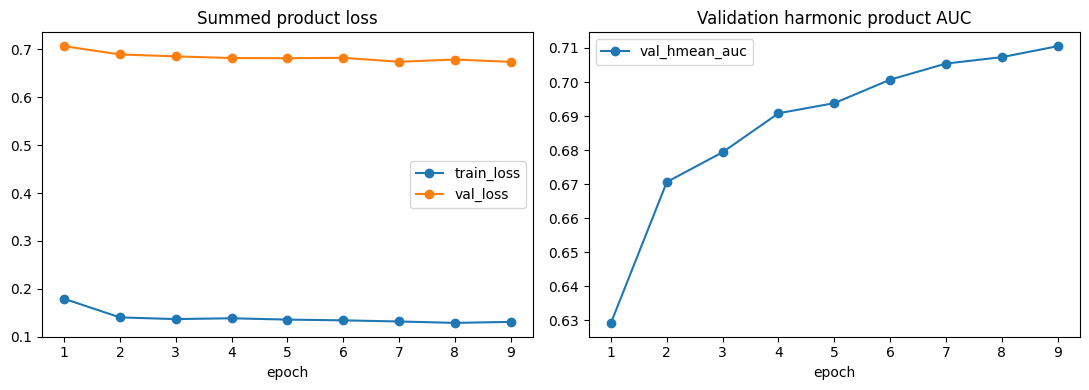

In [480]:
loaders = {}
for split_name in ["train", "valid", "test"]:
    dataset = NpzSequenceDataset(
        shard_paths(split_name),
        global_features=global_features_by_split[split_name],
        shuffle=(split_name == "train"),
    )
    loaders[split_name] = DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        collate_fn=collate,
        pin_memory=(device.type == "cuda")
    )
    
history = train_model(
    model, loaders['train'], loaders["valid"], EPOCHS + 6, "main", lr=1e-4
)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
history.plot(x="epoch", y=["train_loss", "val_loss"], marker="o",
             ax=axes[0], title="Summed product loss")
history.plot(x="epoch", y="val_hmean_auc", marker="o", ax=axes[1],
             title="Validation harmonic product AUC")
plt.tight_layout()


In [481]:
features = pd.read_parquet("/kaggle/input/datasets/ahm352/t-intensive-features")
_, LSTM_FULL_HMEAN_AUC, lstm_y, lstm_p, lstm_ids, lstm_product = evaluate(
    model, loaders["test"], product_values
)
predictions = pd.DataFrame({"app_id": lstm_ids, "target": lstm_y,
                            "product": lstm_product, "probability": lstm_p})

boost_test_ids = set(features.loc[test_mask, "app_id"])

common = predictions[predictions["app_id"].isin(boost_test_ids)]

if len(common) != len(boost_test_ids):
    raise ValueError("Не все CatBoost test app_id найдены в LSTM shards")

boost_common = features.loc[test_mask, ["app_id", "product", "flag"]].copy()

same_test = boost_common.merge(
    common.rename(columns={"probability": "lstm_probability"}),
    on=["app_id", "product"], validate="one_to_one",
)

lstm_table = product_auc_table(
    same_test["target"], same_test["lstm_probability"], same_test["product"],
    product_values,
).rename(columns={"auc": "lstm_auc"}).drop(columns="n")

print(f"LSTM full-test harmonic product AUC: {LSTM_FULL_HMEAN_AUC:.6f}")

LSTM full-test harmonic product AUC: 0.716688


**Вывод:** Гипотеза оправдалась, но до бустинга не дотягиваем :(

## Функция потерь для больших потерь.
Из EDA мы знаем, что у нашего таргета лютый дизбаланс, поэтому попробуем немного переписать наше обучение, чтобы модель минимизировала не изначальный функционал, а какой-то необычный, который бы нивелировал заданные дизбаланс. Итак, **гипотеза:** смена функции потерь на адаптированную к дизбалансам приведёт к увеличению метрики.

In [486]:
from torchvision.ops import sigmoid_focal_loss

def train_one_epoch(model, loader, optimizer):
    model.train()
    losses = []
    alpha = 0.25
    gamma = 2.0
    for batch in loader:
        optimizer.zero_grad(set_to_none=True)
        logits = model(
            batch["cats"].to(device),
            batch["cont"].to(device),
            batch["length"],
            batch["product"].to(device),
        )
        target = batch["target"].to(device)
        product = batch["product"].to(device)
        selected_logits = logits
        loss = sigmoid_focal_loss(selected_logits, target, alpha=alpha, gamma=gamma, reduction="mean")
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        losses.append(loss.item())
    return float(np.mean(losses))

def train_model(model, train_loader, valid_loader,
                epochs, run_name, lr=2e-3):
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="max", patience=1, factor=0.5
    )

    checkpoint_path = Path("/kaggle/working") / f"{run_name}_best.pt"
    best_auc = -np.inf
    history = []

    for epoch in range(1, epochs + 1):
        started = time.perf_counter()
        print(f"Epoch {epoch}/{epochs}")

        train_loss = train_one_epoch(model, train_loader, optimizer)
        val_loss, val_auc, *_ = evaluate(model, valid_loader)
        scheduler.step(val_auc)

        row = {
            "epoch": epoch,
            "train_loss": train_loss,
            "val_loss": val_loss,
            "val_hmean_auc": val_auc,
            "lr": optimizer.param_groups[0]["lr"],
            "seconds": time.perf_counter() - started,
        }
        history.append(row)

        print(
            f"Epoch {epoch}/{epochs}: "
            f"train_loss={train_loss:.4f}, "
            f"val_loss={val_loss:.4f}, "
            f"val_hmean_auc={val_auc:.6f}"
        )

        if val_auc > best_auc:
            best_auc = val_auc
            torch.save(model.state_dict(), checkpoint_path)

    model.load_state_dict(
        torch.load(checkpoint_path, map_location=device, weights_only=True)
    )
    return pd.DataFrame(history)

@torch.no_grad()
def evaluate(model, loader, expected_products=None):
    model.eval()
    logits_all, targets, product_indices, application_ids = [], [], [], []
    for batch in loader:
        logits = model(
            batch["cats"].to(device), batch["cont"].to(device),
            batch["length"], batch["product"].to(device),
        )
        logits_all.append(logits.cpu())
        targets.append(batch["target"])
        product_indices.append(batch["product"])
        application_ids.append(batch["app_id"])
    logits = torch.cat(logits_all)
    target = torch.cat(targets)
    product_index = torch.cat(product_indices)
    loss_fn = torch.nn.BCEWithLogitsLoss()
    loss = loss_fn(logits, target).item()
    probabilities = torch.sigmoid(logits).numpy()
    product = np.asarray(product_values)[product_index.numpy()]
    metric, _ = product_harmonic_auc(
        target.numpy(), probabilities, product, expected_products
    )
    return (loss, metric, target.numpy(), probabilities,
            torch.cat(application_ids).numpy(), product)

In [487]:
n_cont = len(CONT_COLS) + len(AGGR_COLS) + 3

model = TripleLargeMultiHeadLSTM(
    VOCAB_SIZES, n_cont, len(product_values)
).to(device)

model, n_cont

(TripleLargeMultiHeadLSTM(
   (embeddings): ModuleList(
     (0): Embedding(13, 20, padding_idx=0)
     (1): Embedding(9, 20, padding_idx=0)
     (2): Embedding(175, 20, padding_idx=0)
     (3): Embedding(24, 20, padding_idx=0)
     (4): Embedding(6, 20, padding_idx=0)
     (5): Embedding(5, 20, padding_idx=0)
     (6): Embedding(9, 20, padding_idx=0)
     (7): Embedding(5, 20, padding_idx=0)
     (8): Embedding(110, 20, padding_idx=0)
     (9): Embedding(26, 20, padding_idx=0)
     (10): Embedding(165, 20, padding_idx=0)
     (11): Embedding(30, 20, padding_idx=0)
     (12): Embedding(9, 20, padding_idx=0)
     (13): Embedding(26, 20, padding_idx=0)
     (14): Embedding(54, 20, padding_idx=0)
   )
   (lstm1): LSTM(320, 128, batch_first=True)
   (lstm2): LSTM(128, 128, batch_first=True)
   (lstm3): LSTM(128, 128, batch_first=True)
   (dropout): Dropout(p=0.2, inplace=False)
   (heads): ModuleList(
     (0-4): 5 x Linear(in_features=128, out_features=1, bias=True)
   )
 ),
 20)

Epoch 1/12
Epoch 1/12: train_loss=0.0165, val_loss=0.2043, val_hmean_auc=0.654492
Epoch 2/12
Epoch 2/12: train_loss=0.0115, val_loss=0.1881, val_hmean_auc=0.676971
Epoch 3/12
Epoch 3/12: train_loss=0.0113, val_loss=0.1943, val_hmean_auc=0.687474
Epoch 4/12
Epoch 4/12: train_loss=0.0111, val_loss=0.1932, val_hmean_auc=0.694146
Epoch 5/12
Epoch 5/12: train_loss=0.0110, val_loss=0.1874, val_hmean_auc=0.701270
Epoch 6/12
Epoch 6/12: train_loss=0.0109, val_loss=0.1699, val_hmean_auc=0.704869
Epoch 7/12
Epoch 7/12: train_loss=0.0108, val_loss=0.1860, val_hmean_auc=0.709394
Epoch 8/12
Epoch 8/12: train_loss=0.0107, val_loss=0.1816, val_hmean_auc=0.709905
Epoch 9/12
Epoch 9/12: train_loss=0.0106, val_loss=0.1870, val_hmean_auc=0.711423
Epoch 10/12
Epoch 10/12: train_loss=0.0105, val_loss=0.1866, val_hmean_auc=0.713927
Epoch 11/12
Epoch 11/12: train_loss=0.0104, val_loss=0.1803, val_hmean_auc=0.712920
Epoch 12/12
Epoch 12/12: train_loss=0.0102, val_loss=0.1729, val_hmean_auc=0.709521


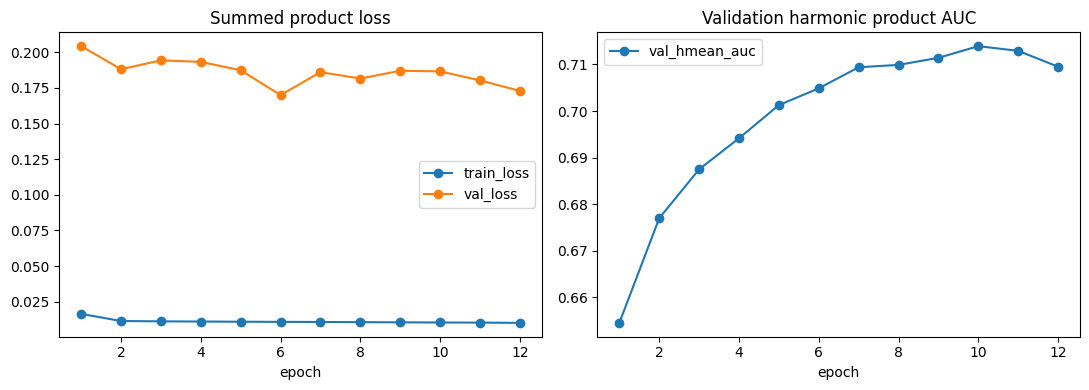

In [488]:
loaders = {}
for split_name in ["train", "valid", "test"]:
    dataset = NpzSequenceDataset(
        shard_paths(split_name),
        global_features=global_features_by_split[split_name],
        shuffle=(split_name == "train"),
    )
    loaders[split_name] = DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        collate_fn=collate,
        pin_memory=(device.type == "cuda")
    )
    
history = train_model(
    model, loaders['train'], loaders["valid"], EPOCHS + 9, "main", lr = 1e-4
)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
history.plot(x="epoch", y=["train_loss", "val_loss"], marker="o",
             ax=axes[0], title="Summed product loss")
history.plot(x="epoch", y="val_hmean_auc", marker="o", ax=axes[1],
             title="Validation harmonic product AUC")
plt.tight_layout()


In [489]:
features = pd.read_parquet("/kaggle/input/datasets/ahm352/t-intensive-features")
_, LSTM_FULL_HMEAN_AUC, lstm_y, lstm_p, lstm_ids, lstm_product = evaluate(
    model, loaders["test"], product_values
)
predictions = pd.DataFrame({"app_id": lstm_ids, "target": lstm_y,
                            "product": lstm_product, "probability": lstm_p})

boost_test_ids = set(features.loc[test_mask, "app_id"])

common = predictions[predictions["app_id"].isin(boost_test_ids)]

if len(common) != len(boost_test_ids):
    raise ValueError("Не все CatBoost test app_id найдены в LSTM shards")

boost_common = features.loc[test_mask, ["app_id", "product", "flag"]].copy()

same_test = boost_common.merge(
    common.rename(columns={"probability": "lstm_probability"}),
    on=["app_id", "product"], validate="one_to_one",
)

lstm_table = product_auc_table(
    same_test["target"], same_test["lstm_probability"], same_test["product"],
    product_values,
).rename(columns={"auc": "lstm_auc"}).drop(columns="n")

print(f"LSTM full-test harmonic product AUC: {LSTM_FULL_HMEAN_AUC:.6f}")

LSTM full-test harmonic product AUC: 0.721161


**Вывод:** Гипотеза оправдалась! И это абсолютный рекорд из всех экспериментров, который наконец позволил обогнать бустинг, хотя, кажется, можно продолжать обучение дальше, так как модель ещё не вышла на плато.

# Итоги.
- EDA. Был произведён анализ данных, в ходе которого были установлены некоторые инсайты о данных, например, изначальное стандартизованность, распределения и отсуствие пропусков, а также была заложена основа для дальнейших гипотез, например, о влиянии большого количества стран в транзакциях на таргет.
- Эксперименты с данными. Были поставлены две гипотезы: первая о том, что использование всех доступных нам фич увеличит итоговое качество модели, что и подтвердилось; вторая, что можно дополнить входные векторы транзакций глобальной информацией о заявке, что тоже действительно привело к увеличению метрики качества.
- Эксперименты с моделью. Увеличили размерность внутренних состояний и глубину самой модели, рассмотрев двуслойную (->, ->) и трёхслойную (->, <-, ->) модели, однако на трёх эпохах гипотезы не оправдались, так как модели просто не сошлись.
- Эксперименты с обучением/loss. Первая гипотеза была самой естественной: увеличить количество эплох и уменьшить lr, что действительно позволило моделям сойтись, поэтому гипотеза подтвердилась. Вторая заключалась в том, чтобы заменить ```BCELoss``` на ```Sigmoid_focal_loss```, который в совокупности с трёхслойной (->, <-, ->)  LSTM на 12 эпохах позволил выбить метрику в $\approx 0.72$, что превзошло бустинг.
- Улучшения: главное направление улучшения - это смена архитектуры, например, на другую RNN, или трансформер, или мамбу. Проблема с лстм и реккурентными в том, что они вообще не параллелятся, из-за чего долго обучаются.